# Matplotlib + SciPy + Seaborn — Complete AI/ML Handbook

**Theory first • When / Why / How • chart selection guide • formulas • colorful plots • interview Q&A • runnable labs**

This single notebook teaches three essential Python libraries for data science and machine learning:
- **Matplotlib** — foundational plotting control and figure customization.
- **SciPy** — scientific computing, probability distributions, statistical tests, optimization, and numerical methods.
- **Seaborn** — high-level statistical visualization built on Matplotlib.

## Study method
1. Read each chapter's theory and "when / why / how" notes.
2. For each chart, first state the question it should answer.
3. Run each lab cell and change one input to observe the result.
4. Practise the interview questions by explaining the concept, use case, assumption, and limitation.
5. In production, pin library versions and make plot choices explicit rather than relying on defaults.

**Color note:** examples use restrained, meaningful palettes and labels. Colors should encode information, remain readable, and not replace clear axes/legends.


## 1. Quick decision guide — which chart should I use?

| Question | Recommended chart | Use it when | Watch out for |
|---|---|---|---|
| What is the distribution of one numeric variable? | Histogram, KDE, ECDF | Shape, skew, tails, percentiles | Histogram bins and KDE bandwidth affect appearance |
| How do distributions differ by group? | Box, violin, strip, ECDF | Compare spread, medians, modes, tails | Show sample sizes; density can mislead for small n |
| How do two numeric variables relate? | Scatter, hexbin, regression plot | Association, clusters, nonlinear trends | Correlation is not causation; overplotting |
| How does a metric change over time? | Line, step, interval band | Ordered time or training epochs | Avoid connecting unordered categories |
| How do categories compare? | Bar, count plot, point plot | Counts or a summary statistic by category | Bar charts usually need a zero baseline |
| How do values vary across a matrix? | Heatmap | Correlation, confusion matrix, grid search | Label scales; use an appropriate colormap |
| How good is a classifier? | Confusion matrix, ROC, PR, calibration | Error types, ranking, rare-event precision, probabilities | AUC does not choose an operating threshold |
| Are regression assumptions plausible? | Residual-vs-fitted, Q-Q, leverage/influence | Error patterns and influential points | No single plot proves all assumptions |
| Is the data drifting? | Overlaid ECDF/histograms, missingness and metric plots | Baseline vs current data | Statistical significance is not operational importance |
| What uncertainty surrounds an estimate? | Error bars, confidence bands, interval plot | Means, model metrics, forecasts | Label whether intervals are SD, SE, CI, or prediction intervals |

### Fundamental distinction
- **Matplotlib:** best when you need precise control over the figure.
- **Seaborn:** best when you need concise statistical plots and grouped comparisons.
- **SciPy:** best when you need statistical calculations, distributions, tests, optimization, integration, or scientific algorithms.


## 2. Formula and API cheat sheet

### Matplotlib
```python
fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
ax.plot(x, y, label="series", color="tab:blue")
ax.set(title="Descriptive title", xlabel="X unit", ylabel="Y unit")
ax.legend()
fig.savefig("figure.png", dpi=160, bbox_inches="tight")
```

### Seaborn
```python
sns.set_theme(style="whitegrid", palette="colorblind")
sns.histplot(data=df, x="value", hue="group", stat="density", common_norm=False)
sns.boxplot(data=df, x="group", y="value")
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, annot=True, square=True)
```

### SciPy statistics
```python
from scipy import stats
stats.norm.cdf(x, loc=mu, scale=sigma)   # P(X <= x)
stats.norm.ppf(0.975)                    # standard-normal quantile
stats.ttest_ind(a, b, equal_var=False)   # Welch two-sample t-test
stats.pearsonr(x, y)                     # linear association
stats.bootstrap((x,), np.mean, confidence_level=0.95)
```

### Statistical formulas to remember

- **$Z$-score standardization**:
  $$z = \frac{x - \mu}{\sigma}$$

- **Standard error of an IID sample mean**:
  $$\text{SE}(\bar{x}) = \frac{s}{\sqrt{n}}$$

- **Pearson correlation coefficient**:
  $$r = \frac{\operatorname{Cov}(X, Y)}{s_X s_Y}$$

- **Welch's $t$-statistic**:
  $$t = \frac{\bar{x}_1 - \bar{x}_2}{\sqrt{\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}}}$$

- **Confidence interval template**:
  $$\text{Estimate} \pm \text{Critical Value} \times \text{Standard Error}$$

- **KDE bandwidth** controls smoothness; it is a tuning choice, not a property of the raw data.

## 3. Theory chapters and expandable interview Q&A

Each question is written as a collapsible HTML disclosure in the notebook renderer when supported. The same content remains readable as Markdown in notebook interfaces that do not render disclosure widgets.

## 1. Visualization foundations and chart selection

<details>
<summary><strong>What is exploratory data analysis (EDA)?</strong></summary>

**Theory / answer:** EDA is the iterative process of summarizing and visualizing data to understand distributions, data quality, relationships, outliers, and possible modelling assumptions before formal modelling.

**When / why / how:** Use histograms/KDE/ECDF for distributions; scatterplots for relationships; box/violin plots for group comparisons; heatmaps for matrices; time plots for temporal data.

**Interview caveat:** EDA can leak information if decisions are repeatedly made using the final test set. Do exploratory analysis on training data, and reserve final evaluation data.

</details>

<details>
<summary><strong>How do you choose the right chart?</strong></summary>

**Theory / answer:** Choose a chart based on the analytical question and variable types: comparison, distribution, relationship, composition, or change over time.

**When / why / how:** Bar charts compare categories; histograms show numeric distributions; line charts show ordered time trends; scatterplots show two numeric variables; box/violin plots compare distributions; heatmaps show matrices.

**Interview caveat:** Do not choose a chart just because it looks attractive. Avoid 3D charts and misleading axes.

</details>

<details>
<summary><strong>Bar chart vs histogram</strong></summary>

**Theory / answer:** A bar chart summarizes categories and typically has gaps between bars. A histogram bins a continuous numeric variable and uses adjacent bars to represent frequencies or densities.

**When / why / how:** Bar chart: product category sales. Histogram: customer age, model latency, residuals.

**Interview caveat:** Histogram shape depends on bin width and bin origin; show units and sample size.

</details>

<details>
<summary><strong>Histogram vs KDE vs ECDF</strong></summary>

**Theory / answer:** A histogram bins values; KDE estimates a smooth density; an empirical CDF shows the fraction of observations at or below each value.

**When / why / how:** Use histogram for intuitive counts, KDE for smooth shape comparisons, ECDF for quantiles and distribution comparisons without binning.

**Interview caveat:** KDE bandwidth changes apparent smoothness; density is not probability at a point.

</details>

<details>
<summary><strong>When should you use a box plot?</strong></summary>

**Theory / answer:** A box plot summarizes median, quartiles, IQR, and often points beyond 1.5×IQR whiskers.

**When / why / how:** Compare numeric distributions across categories, e.g., latency by model version or scores by class.

**Interview caveat:** A box plot hides multimodality and sample-size differences; pair it with points or a violin plot when useful.

</details>

<details>
<summary><strong>When should you use a violin plot?</strong></summary>

**Theory / answer:** A violin plot combines a density shape with summary information, often including quartiles or median.

**When / why / how:** Compare distribution shape across groups when multimodality matters.

**Interview caveat:** Density shapes depend on bandwidth and may mislead for small samples.

</details>

<details>
<summary><strong>When should you use a scatterplot?</strong></summary>

**Theory / answer:** A scatterplot displays paired observations for two quantitative variables.

**When / why / how:** Explore linear/nonlinear association, clusters, heteroscedasticity, and outliers; add regression or smooth trend lines only when justified.

**Interview caveat:** Overplotting hides density; use transparency, hexbin, sampling, or aggregation for large datasets.

</details>

<details>
<summary><strong>When should you use a line chart?</strong></summary>

**Theory / answer:** A line chart connects values along a meaningful ordered axis, commonly time.

**When / why / how:** Time-series trends, training loss by epoch, latency over release versions, and metric monitoring.

**Interview caveat:** Connecting unordered categories implies a continuity that may not exist.

</details>

<details>
<summary><strong>When should you use a heatmap?</strong></summary>

**Theory / answer:** A heatmap maps values in a matrix to color.

**When / why / how:** Correlation matrices, confusion matrices, missingness patterns, feature-by-feature summaries, and grid search scores.

**Interview caveat:** Use a meaningful color scale, label axes, and avoid implying equal numeric differences when the palette is not perceptually ordered.

</details>

<details>
<summary><strong>When should you use a pair plot?</strong></summary>

**Theory / answer:** A pair plot shows pairwise relationships among selected variables, often with univariate distributions on the diagonal.

**When / why / how:** Quick EDA on a small-to-moderate set of numeric features.

**Interview caveat:** It scales quadratically with feature count and can become unreadable; sample rows or choose a subset.

</details>

<details>
<summary><strong>What are color, hue, and colormap best practices?</strong></summary>

**Theory / answer:** Use color to encode a meaningful variable, not as decoration. Sequential palettes represent ordered magnitude; diverging palettes emphasize deviation around a midpoint; qualitative palettes distinguish categories.

**When / why / how:** Use hue for class/group categories; sequential colors for counts or rates; diverging colors for correlations centered on zero.

**Interview caveat:** Keep colorblind accessibility, sufficient contrast, and consistent mappings across figures.

</details>

<details>
<summary><strong>What makes a chart production-quality?</strong></summary>

**Theory / answer:** A clear chart has a question-driven title, labelled axes and units, legible scale, useful legend, honest baseline, appropriate uncertainty, and reproducible data/code.

**When / why / how:** Use constrained layout/tight layout, meaningful tick formatting, source/sample notes, and consistent styling.

**Interview caveat:** A polished figure must not hide missing data, uncertainty, or inconvenient groups.

</details>


## 2. Matplotlib fundamentals and chart types

<details>
<summary><strong>What is Matplotlib and when should you use it?</strong></summary>

**Theory / answer:** Matplotlib is a foundational Python visualization library offering fine-grained control over static plots, axes, artists, annotations, layout, and file export.

**When / why / how:** Use it for publication-quality figures, customized subplots, scientific plots, annotations, and integration with NumPy/Pandas/SciPy.

**Interview caveat:** For rapid statistical plots, Seaborn can be more concise; Matplotlib remains the control layer underneath many libraries.

</details>

<details>
<summary><strong>pyplot vs object-oriented API</strong></summary>

**Theory / answer:** The pyplot API uses stateful commands such as plt.plot; the object-oriented API uses fig, ax = plt.subplots() and methods like ax.plot.

**When / why / how:** Prefer the object-oriented API for reusable functions, multiple axes, dashboards, and reliable formatting.

**Interview caveat:** Stateful pyplot commands can target the wrong axes in complex figures.

</details>

<details>
<summary><strong>Figure vs Axes vs Axis</strong></summary>

**Theory / answer:** Figure is the whole canvas; Axes is one plotting area; Axis manages coordinate scale, ticks, and tick labels.

**When / why / how:** Create figures with plt.subplots; customize each Axes via set_title, set_xlabel, set_ylabel, legend, and grid.

**Interview caveat:** The plural Axes object is different from an individual x/y Axis.

</details>

<details>
<summary><strong>How do you create multiple subplots?</strong></summary>

**Theory / answer:** Use plt.subplots(rows, cols, figsize=...) to get a Figure and one or more Axes objects.

**When / why / how:** Compare distributions, metrics, or model versions in a consistent layout.

**Interview caveat:** Set sharex/sharey only when shared scales make comparisons fair; use squeeze=False for predictable 2D indexing.

</details>

<details>
<summary><strong>How do you add labels, legends, annotations, and grid?</strong></summary>

**Theory / answer:** Set informative titles and axis labels, label plotted series, call legend when labels exist, annotate notable points, and use a subtle grid when it improves reading.

**When / why / how:** Useful for model metrics, scientific data, and communicating key observations.

**Interview caveat:** Annotations should clarify the plot rather than obscure data.

</details>

<details>
<summary><strong>How do you save a figure correctly?</strong></summary>

**Theory / answer:** Use fig.savefig(path, dpi=..., bbox_inches='tight', facecolor=...) before closing the figure.

**When / why / how:** PNG for slides/web; SVG/PDF for vector output; high DPI for raster print.

**Interview caveat:** Save the Figure object explicitly; avoid relying on whichever figure pyplot currently considers active.

</details>

<details>
<summary><strong>Line, bar, scatter, and step plots</strong></summary>

**Theory / answer:** Line plots show ordered trends; bar plots compare categories; scatter plots show paired observations; step plots represent piecewise-constant changes.

**When / why / how:** Choose according to variable type and ordering; use error bars or confidence bands where relevant.

**Interview caveat:** For bars, start at zero when comparing magnitude unless a different scale is clearly justified.

</details>

<details>
<summary><strong>Error bars and uncertainty bands</strong></summary>

**Theory / answer:** Error bars represent a stated quantity such as SD, SE, or a confidence interval; shaded bands can represent uncertainty around a fitted curve.

**When / why / how:** Experimental results, repeated model scores, scientific measurements, and forecast intervals.

**Interview caveat:** Always specify what the bars mean and whether intervals are pointwise or simultaneous.

</details>

<details>
<summary><strong>Log scales and axis transformations</strong></summary>

**Theory / answer:** Log scales display multiplicative ranges compactly; transformations can help visualize skewed positive data or exponential relationships.

**When / why / how:** Latency, counts, loss curves, power-law-like distributions, and wide dynamic ranges.

**Interview caveat:** Zero and negative values need special handling; label transformed axes and don't use log scale just to make a plot look linear.

</details>

<details>
<summary><strong>How do you plot a confusion matrix?</strong></summary>

**Theory / answer:** Compute a confusion matrix from true and predicted labels, then display it with imshow or a heatmap, with class names and a colorbar.

**When / why / how:** Classification error analysis and subgroup comparisons.

**Interview caveat:** Normalize by true labels or predicted labels only when that denominator matches the question; label normalization clearly.

</details>

<details>
<summary><strong>How do you plot model learning curves?</strong></summary>

**Theory / answer:** Plot training and validation scores/loss against training size or epochs.

**When / why / how:** Diagnose underfitting, overfitting, convergence, and whether more data might help.

**Interview caveat:** Ensure metrics and axes are comparable and validation data is not used to fit the model.

</details>

<details>
<summary><strong>How do you visualize residuals?</strong></summary>

**Theory / answer:** Plot residuals against fitted values and predictors, plus a residual distribution or Q-Q plot where relevant.

**When / why / how:** Detect nonlinearity, heteroscedasticity, outliers, and misspecified error structure.

**Interview caveat:** A residual histogram alone cannot verify all regression assumptions.

</details>

<details>
<summary><strong>How do you create a Q-Q plot?</strong></summary>

**Theory / answer:** A quantile-quantile plot compares sample quantiles with theoretical quantiles or another sample's quantiles.

**When / why / how:** Assess whether residuals roughly follow a reference distribution, or compare distributions.

**Interview caveat:** Interpret systematic deviations and tail behavior; a Q-Q plot is diagnostic, not a formal proof.

</details>

<details>
<summary><strong>How do you avoid overlapping labels?</strong></summary>

**Theory / answer:** Use constrained_layout=True, fig.tight_layout(), rotated ticks, concise labels, and figure sizing; manually adjust only when needed.

**When / why / how:** Dense categorical charts, dates, dashboards, and multi-panel figures.

**Interview caveat:** Don't shrink fonts until labels are unreadable; simplify or split the chart.

</details>


## 3. Seaborn statistical visualization

<details>
<summary><strong>What is Seaborn?</strong></summary>

**Theory / answer:** Seaborn is a high-level statistical visualization library built on Matplotlib. It provides attractive defaults and concise plotting for distributions, relationships, categorical comparisons, and statistical estimates.

**When / why / how:** Use it for EDA, grouped distributions, regression plots, categorical plots, pair plots, and correlation heatmaps.

**Interview caveat:** For exact low-level control, access the Matplotlib Figure/Axes or use Matplotlib directly.

</details>

<details>
<summary><strong>How do figure-level and axes-level Seaborn functions differ?</strong></summary>

**Theory / answer:** Axes-level functions draw on a supplied Axes and typically return an Axes; figure-level functions such as relplot, displot, and catplot manage a FacetGrid and can facet across variables.

**When / why / how:** Use axes-level functions to compose custom Matplotlib layouts; figure-level functions for faceting and small multiples.

**Interview caveat:** Don't pass an Axes argument to a figure-level function unless its API explicitly supports it.

</details>

<details>
<summary><strong>What is hue in Seaborn?</strong></summary>

**Theory / answer:** Hue maps a variable to color, often distinguishing categories or encoding a continuous variable.

**When / why / how:** Compare class-specific distributions, groups, or outcomes within the same chart.

**Interview caveat:** Use a consistent palette and avoid too many categories.

</details>

<details>
<summary><strong>What is FacetGrid and when should you use faceting?</strong></summary>

**Theory / answer:** Faceting creates multiple comparable panels split by one or more categorical variables.

**When / why / how:** Compare relationships by region, class, model family, or cohort while keeping axes consistent.

**Interview caveat:** Too many facets produce tiny plots; share scales when cross-panel comparisons are intended.

</details>

<details>
<summary><strong>How do you use histplot, kdeplot, and ecdfplot?</strong></summary>

**Theory / answer:** histplot shows binned frequencies/density; kdeplot estimates smooth density; ecdfplot shows empirical cumulative probability.

**When / why / how:** Use histplot for counts and shape, KDE for smooth distribution comparisons, ECDF for quantiles and tail comparisons.

**Interview caveat:** Choose common bins/bandwidths for fair group comparisons; account for discrete data.

</details>

<details>
<summary><strong>How do you use boxplot, violinplot, and stripplot?</strong></summary>

**Theory / answer:** Boxplot summarizes quartiles; violinplot shows density shape; stripplot shows individual observations with jitter.

**When / why / how:** Combine a violin/box plot with points when both distribution shape and sample observations matter.

**Interview caveat:** Large samples can create overplotting; swarmplot can be expensive for many observations.

</details>

<details>
<summary><strong>What does regplot or lmplot show?</strong></summary>

**Theory / answer:** regplot fits and visualizes a regression relationship for two variables; lmplot supports facets and hue-style grouping in a figure-level interface.

**When / why / how:** Explore linear association and confidence bands; compare group-specific relationships.

**Interview caveat:** An observational fitted line does not establish causation, and default confidence intervals have assumptions.

</details>

<details>
<summary><strong>How do you create a correlation heatmap?</strong></summary>

**Theory / answer:** Compute correlations, then pass the matrix to sns.heatmap with annotations, a diverging palette, and a centered zero.

**When / why / how:** Feature correlation EDA, multicollinearity screening, and compact relationship summaries.

**Interview caveat:** Correlation is pairwise and can miss nonlinear or conditional relationships.

</details>

<details>
<summary><strong>How do countplot and barplot differ?</strong></summary>

**Theory / answer:** countplot counts observations per category. barplot estimates a numeric statistic (mean by default in many versions) for each category and may show uncertainty.

**When / why / how:** Countplot for category frequencies; barplot for average outcome by group.

**Interview caveat:** Specify estimator/errorbar behavior when the estimand matters; APIs have changed across Seaborn versions.

</details>

<details>
<summary><strong>How do you set themes and palettes?</strong></summary>

**Theory / answer:** sns.set_theme controls global aesthetics; palette choices should reflect category vs magnitude semantics.

**When / why / how:** Use consistent themes across notebook reports and reusable plotting functions.

**Interview caveat:** Avoid changing global settings unexpectedly in shared notebooks; record versions for reproducibility.

</details>

<details>
<summary><strong>How do you visualize uncertainty in Seaborn?</strong></summary>

**Theory / answer:** Many statistical plots show confidence intervals or error bars for estimates; configure the relevant errorbar/ci argument for the installed version.

**When / why / how:** Group mean comparisons, regression trends, and estimated relationships.

**Interview caveat:** A confidence interval is not the range containing most individual observations.

</details>

<details>
<summary><strong>What is a pairplot and when is it useful?</strong></summary>

**Theory / answer:** pairplot displays pairwise numeric relationships and marginal distributions, optionally colored by a category.

**When / why / how:** Early EDA to spot correlations, clusters, outliers, and possible nonlinear patterns.

**Interview caveat:** It is expensive and cluttered for many features; select a manageable subset.

</details>

<details>
<summary><strong>How do you make plots reproducible?</strong></summary>

**Theory / answer:** Pin package versions when needed, set random seeds for sampling, specify estimators/bins/palettes, label units, and keep data transformations in code.

**When / why / how:** Research reports, model cards, monitoring notebooks, and collaborative analysis.

**Interview caveat:** A seed alone does not guarantee identical rendering across library versions or backends.

</details>


## 4. SciPy statistics and scientific computing

<details>
<summary><strong>What is SciPy and how does it differ from NumPy?</strong></summary>

**Theory / answer:** NumPy provides core arrays and numerical operations. SciPy builds on NumPy with scientific algorithms such as statistics, optimization, integration, signal processing, interpolation, sparse matrices, and spatial algorithms.

**When / why / how:** Use scipy.stats for probability distributions and statistical tests; scipy.optimize for fitting/optimization; scipy.linalg for advanced linear algebra.

**Interview caveat:** Choose the correct API and inspect assumptions and return values; don't use a test solely because it is available.

</details>

<details>
<summary><strong>What is scipy.stats?</strong></summary>

**Theory / answer:** scipy.stats contains distributions, summary statistics, hypothesis tests, correlation tests, resampling tools, and related probability functions.

**When / why / how:** Use it for t-tests, chi-square tests, distribution CDF/PPF, bootstrap, permutation tests, and goodness-of-fit work.

**Interview caveat:** Check SciPy version and function signature because some APIs evolve.

</details>

<details>
<summary><strong>PDF vs CDF vs PPF vs SF</strong></summary>

**Theory / answer:** PDF/PMF describe density/probability; CDF gives P(X≤x); PPF is the inverse CDF (quantile); SF gives P(X>x) and can be numerically more stable in tails.

**When / why / how:** Compute probabilities, quantiles, confidence limits, and tail risk for distributions.

**Interview caveat:** For discrete distributions, PMF rather than PDF gives point probabilities.

</details>

<details>
<summary><strong>How do you use a SciPy distribution?</strong></summary>

**Theory / answer:** Instantiate or call a distribution such as stats.norm(loc=mu, scale=sigma), then use pdf, cdf, ppf, rvs, mean, and var.

**When / why / how:** Probability calculations, simulation, interval calculations, and model assumptions.

**Interview caveat:** Parameter names differ by distribution; scale is standard deviation for normal, not variance.

</details>

<details>
<summary><strong>When do you use t-test, Welch's t-test, and paired t-test?</strong></summary>

**Theory / answer:** One-sample t-tests compare a mean to a value; independent t-tests compare two independent means; Welch's test allows unequal variances; paired tests analyze within-pair differences.

**When / why / how:** Use Welch by default for two independent means unless equal variances are justified; use paired when measurements are naturally matched.

**Interview caveat:** The independent unit and assignment design matter more than a quick normality test.

</details>

<details>
<summary><strong>When do you use Mann–Whitney or Wilcoxon signed-rank?</strong></summary>

**Theory / answer:** Mann–Whitney is a rank-based test for two independent samples; Wilcoxon signed-rank is for paired differences and has a symmetric-difference assumption for a location interpretation.

**When / why / how:** Skewed data or rank-based comparisons when those hypotheses match the question.

**Interview caveat:** Mann–Whitney is not universally a median test; distributions with different shapes complicate interpretation.

</details>

<details>
<summary><strong>When do you use chi-square and Fisher exact tests?</strong></summary>

**Theory / answer:** Chi-square tests approximate categorical association/goodness-of-fit; Fisher exact calculates an exact conditional result for small contingency tables.

**When / why / how:** A/B conversion by category, independence tables, and categorical data analysis.

**Interview caveat:** Expected cell counts, fixed margins, independence, and study design determine validity.

</details>

<details>
<summary><strong>What is a permutation test?</strong></summary>

**Theory / answer:** A permutation test creates a null distribution by rearranging labels or values in a way allowed by the null hypothesis and design.

**When / why / how:** Useful when a test statistic has a difficult analytic distribution or in randomized experiments.

**Interview caveat:** Permute at the correct unit and preserve pairing, clusters, or randomization restrictions.

</details>

<details>
<summary><strong>What is bootstrap and how does SciPy support it?</strong></summary>

**Theory / answer:** Bootstrap resamples observed units with replacement to approximate a statistic's sampling distribution. SciPy offers bootstrap utilities for confidence intervals.

**When / why / how:** Confidence intervals for medians, model metrics, and complex statistics.

**Interview caveat:** Use paired=True for paired samples and design-aware resampling for clusters/time series.

</details>

<details>
<summary><strong>How do you calculate Pearson and Spearman correlation?</strong></summary>

**Theory / answer:** Pearson measures linear association; Spearman measures rank-based monotonic association.

**When / why / how:** Pearson for roughly linear relationships; Spearman for monotonic relationships or reduced sensitivity to extreme values.

**Interview caveat:** Neither establishes causality; tie handling and dependence affect inference.

</details>

<details>
<summary><strong>What is a goodness-of-fit test?</strong></summary>

**Theory / answer:** A goodness-of-fit test compares observed data with a specified distribution or expected frequency pattern.

**When / why / how:** Distribution checks and categorical expected-count comparisons.

**Interview caveat:** Parameter estimation from the same data can change the reference distribution; use the appropriate test variant.

</details>

<details>
<summary><strong>What are optimization and root-finding in SciPy?</strong></summary>

**Theory / answer:** scipy.optimize provides routines for minimizing objective functions, fitting parameters, solving roots, and constrained optimization.

**When / why / how:** Maximum likelihood, curve fitting, parameter estimation, and numerical calibration.

**Interview caveat:** Check convergence flags, gradients, parameter bounds, scaling, and multiple local optima.

</details>

<details>
<summary><strong>When should you use scipy.linalg instead of numpy.linalg?</strong></summary>

**Theory / answer:** Both provide linear algebra. scipy.linalg offers additional routines and often richer options for decompositions and matrix functions.

**When / why / how:** Scientific computing, decompositions, matrix exponentials, and structured linear algebra.

**Interview caveat:** Avoid explicit matrix inverses when solving systems; use solve or least-squares routines.

</details>

<details>
<summary><strong>What is numerical integration in SciPy?</strong></summary>

**Theory / answer:** Numerical integration approximates an integral from function evaluations, e.g. scipy.integrate.quad for one-dimensional integrals.

**When / why / how:** Expected values, likelihood normalizers, areas, and scientific models without closed-form integrals.

**Interview caveat:** Check error estimates, integration limits, discontinuities, and convergence.

</details>


## 5. Scientific statistics concepts and formulas

<details>
<summary><strong>What is a probability distribution?</strong></summary>

**Theory / answer:** A distribution describes how probability is allocated over possible outcomes. Discrete distributions use PMFs; continuous distributions use PDFs and CDFs.

**When / why / how:** Choose distributions aligned with target support and data-generation process.

**Interview caveat:** A distributional assumption is a model, not a fact inferred from a single plot.

</details>

<details>
<summary><strong>What is the normal distribution used for?</strong></summary>

**Theory / answer:** The normal distribution is symmetric and described by mean μ and standard deviation σ; z=(x−μ)/σ standardizes a normal variable.

**When / why / how:** Gaussian measurement noise, linear-model errors under assumptions, approximate sampling distributions, and z-based calculations.

**Interview caveat:** Raw predictors need not be normal for many ML algorithms.

</details>

<details>
<summary><strong>What is the binomial distribution?</strong></summary>

**Theory / answer:** For n independent trials with success probability p, the number of successes follows Binomial(n,p), with mean np and variance np(1−p).

**When / why / how:** Conversion counts, binary outcomes over fixed trials, and proportion uncertainty.

**Interview caveat:** Trials must be independent with constant success probability for the simple model.

</details>

<details>
<summary><strong>What is the Poisson distribution?</strong></summary>

**Theory / answer:** Poisson models counts over a fixed exposure with rate λ; its mean and variance are λ under the model.

**When / why / how:** Event counts, support tickets, arrivals, and Poisson regression.

**Interview caveat:** Overdispersion and varying exposure may require another model or an offset.

</details>

<details>
<summary><strong>What are quantiles and percentiles?</strong></summary>

**Theory / answer:** The q-quantile is a threshold with roughly q fraction of observations at or below it; the 95th percentile is a common upper-tail summary.

**When / why / how:** p95/p99 latency, service-level objectives, robust reporting, and forecast targets.

**Interview caveat:** Quantile definitions/interpolation can differ among packages for small samples.

</details>

<details>
<summary><strong>What are confidence intervals and p-values?</strong></summary>

**Theory / answer:** A confidence interval is a procedure with long-run coverage; a p-value measures how extreme data are under a specified null model.

**When / why / how:** Inference and experiments, interpreted with effect sizes and design assumptions.

**Interview caveat:** A p-value is not the probability the null is true; a CI is not a prediction interval.

</details>

<details>
<summary><strong>What is the law of large numbers vs the central limit theorem?</strong></summary>

**Theory / answer:** LLN says sample averages converge to an expected value under suitable conditions. CLT describes the approximate sampling distribution of standardized averages.

**When / why / how:** LLN explains stable averages; CLT motivates approximate inference for means.

**Interview caveat:** Dependence, heavy tails, and small samples can complicate both.

</details>

<details>
<summary><strong>What is covariance vs correlation?</strong></summary>

**Theory / answer:** Covariance has scale-dependent units and measures joint variation; correlation standardizes covariance and ranges from −1 to 1.

**When / why / how:** Covariance matrices for PCA/Gaussian models; correlation for unitless pairwise association.

**Interview caveat:** Correlation can miss nonlinear dependence.

</details>

<details>
<summary><strong>What is a robust statistic?</strong></summary>

**Theory / answer:** A robust statistic is relatively insensitive to some outliers or model deviations.

**When / why / how:** Median, IQR, MAD, rank tests, robust regression, and robust scaling.

**Interview caveat:** Robustness is relative to a specified contamination model, not universal immunity.

</details>

<details>
<summary><strong>What is multiple testing correction?</strong></summary>

**Theory / answer:** Testing many hypotheses increases false-positive risk. Bonferroni controls family-wise error; Benjamini–Hochberg controls false discovery rate under suitable conditions.

**When / why / how:** Feature screens, large experiment programs, and many subgroup comparisons.

**Interview caveat:** Pre-specify primary outcomes and distinguish confirmatory from exploratory analysis.

</details>

<details>
<summary><strong>What is statistical power?</strong></summary>

**Theory / answer:** Power is the probability of rejecting the null for a specified alternative when that alternative is true; it depends on effect size, noise, sample size, and test design.

**When / why / how:** A/B test planning, model comparisons, and quality-control design.

**Interview caveat:** A non-significant result may reflect low power rather than no effect.

</details>

<details>
<summary><strong>What is effect size?</strong></summary>

**Theory / answer:** Effect size expresses magnitude, e.g. mean difference, standardized mean difference, odds ratio, or risk ratio.

**When / why / how:** Interpret practical importance and design studies.

**Interview caveat:** Statistical significance does not reveal practical impact.

</details>

<details>
<summary><strong>What is the bias–variance trade-off?</strong></summary>

**Theory / answer:** Under squared-error assumptions, expected prediction error can be understood as bias squared plus variance plus irreducible noise.

**When / why / how:** Diagnose underfit/overfit and select model complexity, regularization, and data volume.

**Interview caveat:** The exact decomposition is assumption-dependent and not universal for all metrics.

</details>

<details>
<summary><strong>What is the difference between correlation and causation?</strong></summary>

**Theory / answer:** Correlation is association; causation concerns how outcomes would change under an intervention. Confounding and selection can create spurious associations.

**When / why / how:** Use randomization or defensible causal designs for causal questions; predictive models answer a different question.

**Interview caveat:** Feature importance does not establish a causal effect.

</details>


## 6. Visual diagnostics for ML and data science

<details>
<summary><strong>Which plots diagnose regression assumptions?</strong></summary>

**Theory / answer:** Residual-vs-fitted plots diagnose mean structure and variance patterns; Q-Q plots inspect residual quantiles; leverage/influence plots help identify influential observations.

**When / why / how:** Linear regression, GLMs, and forecasting residuals.

**Interview caveat:** No single plot proves all assumptions; combine plots with domain knowledge and sensitivity checks.

</details>

<details>
<summary><strong>Which plots help diagnose classification?</strong></summary>

**Theory / answer:** Confusion matrices show error types; ROC and precision-recall curves show threshold trade-offs; calibration curves assess probability reliability.

**When / why / how:** Imbalanced classification, threshold setting, risk scoring, and model comparison.

**Interview caveat:** ROC-AUC can look strong while precision is poor at low prevalence; use operational metrics.

</details>

<details>
<summary><strong>Which plots help diagnose data drift?</strong></summary>

**Theory / answer:** Compare baseline/current histograms, ECDFs, categorical proportions, missingness, score distributions, and outcome/calibration plots.

**When / why / how:** Production monitoring and retraining decisions.

**Interview caveat:** A significant distribution test is not automatically a business problem; use thresholds and effect sizes.

</details>

<details>
<summary><strong>How should you visualize uncertainty?</strong></summary>

**Theory / answer:** Use error bars, confidence bands, bootstrap distributions, interval plots, or posterior distributions, with clear definitions.

**When / why / how:** Experiments, estimates, forecasts, and model performance comparisons.

**Interview caveat:** Avoid mixing SD, SE, and confidence intervals without labeling.

</details>

<details>
<summary><strong>How do you plot feature importance responsibly?</strong></summary>

**Theory / answer:** Plot permutation importance or model-specific importance with labels and uncertainty where feasible, and compare correlated features carefully.

**When / why / how:** Explain model behavior and prioritize data-quality investigations.

**Interview caveat:** Importance is model-dependent and noncausal; correlated predictors can share or mask importance.

</details>

<details>
<summary><strong>How do you visualize class imbalance?</strong></summary>

**Theory / answer:** Use a bar chart of class counts/proportions and show subgroup counts alongside metrics.

**When / why / how:** Fraud, anomaly detection, rare disease, and skewed labels.

**Interview caveat:** Do not rely on accuracy alone; add PR-AUC, recall/precision, calibration, and cost-aware thresholding.

</details>

<details>
<summary><strong>How do you visualize missing data?</strong></summary>

**Theory / answer:** Use missingness-rate bars, a matrix/heatmap, and missingness by time or subgroup.

**When / why / how:** Data pipeline quality, survey datasets, and training/serving skew.

**Interview caveat:** Missingness may be informative; investigate mechanisms rather than blindly dropping rows.

</details>


## 7. Interview scenario bank and debugging judgment

<details>
<summary><strong>A chart looks different after upgrading Seaborn. What do you do?</strong></summary>

**Theory / answer:** Check library versions and API changes, explicitly specify estimator/errorbar/palette/order, and compare a small known example.

**When / why / how:** Pin dependencies for reproducible reporting and inspect release notes when behavior changes.

**Interview caveat:** Avoid assuming defaults remain constant across versions.

</details>

<details>
<summary><strong>A p-value is 0.03. Can you claim the model is better?</strong></summary>

**Theory / answer:** Not from the p-value alone. Check pre-specified hypothesis, effect size, uncertainty, multiplicity, paired evaluation, test-set independence, and practical impact.

**When / why / how:** Paired bootstrap or an appropriate test can compare model errors/scores on the same cases.

**Interview caveat:** A tiny statistically significant difference may not be operationally meaningful.

</details>

<details>
<summary><strong>Your histogram changes drastically when bins change. Is the data wrong?</strong></summary>

**Theory / answer:** Not necessarily; histograms depend on bin width and origin. Compare a few justified bin rules and use ECDF or KDE as complementary views.

**When / why / how:** Distribution EDA and drift checks.

**Interview caveat:** KDE has bandwidth sensitivity too, and neither plot replaces domain checks.

</details>

<details>
<summary><strong>A correlation heatmap shows high correlation. Should you remove a feature?</strong></summary>

**Theory / answer:** Not automatically. Determine whether the goal is coefficient interpretation, predictive performance, stability, or causal estimation.

**When / why / how:** VIF/conditioning diagnostics for linear inference; regularization and CV for prediction.

**Interview caveat:** Correlated features can be useful and may not hurt all algorithms equally.

</details>

<details>
<summary><strong>A Seaborn barplot shows a mean and an error bar. What is the error bar?</strong></summary>

**Theory / answer:** Its meaning depends on Seaborn version and the configured errorbar/ci setting; explicitly set and document the uncertainty definition.

**When / why / how:** Group estimates in EDA and reports.

**Interview caveat:** Do not call it a standard deviation or confidence interval unless the configuration says so.

</details>

<details>
<summary><strong>The scipy test returns a small p-value but the data are clustered. What is wrong?</strong></summary>

**Theory / answer:** The test may treat correlated rows as independent, underestimating uncertainty. Use cluster-aware design, aggregation, cluster-robust methods, or cluster bootstrap.

**When / why / how:** User/session/household/region-level data and repeated measures.

**Interview caveat:** The independent unit is determined by sampling/assignment design, not the number of rows.

</details>

<details>
<summary><strong>How would you build a reusable plotting function?</strong></summary>

**Theory / answer:** Accept data/column names/Axes, validate inputs, label axes, return the Figure/Axes, avoid hidden global state, and separate transformation from presentation.

**When / why / how:** Reusable EDA notebooks, monitoring, and model reports.

**Interview caveat:** Test missing values, empty groups, and edge cases.

</details>

<details>
<summary><strong>How do you make a notebook colorful but professional?</strong></summary>

**Theory / answer:** Use a consistent theme, restrained palette, clear hierarchy, descriptive titles, units, and color semantics. Use contrasting colors sparingly for emphasis.

**When / why / how:** Teaching handbooks, stakeholder reports, and portfolio projects.

**Interview caveat:** Color should encode information and remain accessible; avoid rainbow scales for ordered values.

</details>


## 4. Additional interview question bank

These questions broaden coverage across chart semantics, SciPy API choices, diagnostics, inference, and production-quality visualization.

<details>
<summary><strong>What is a rug plot?</strong></summary>

**Answer:** A rug plot marks each observation as a small tick along an axis.

**Use:** Pair with histograms/KDE to show actual sample locations.

**Caveat:** Overlapping ticks hide density for large datasets.

</details>

<details>
<summary><strong>What is a hexbin plot?</strong></summary>

**Answer:** A hexbin plot bins 2D observations into hexagonal cells and encodes count or another aggregate.

**Use:** Large scatter datasets with overplotting.

**Caveat:** Choose grid size and normalization deliberately.

</details>

<details>
<summary><strong>What is a contour plot?</strong></summary>

**Answer:** Contours connect locations with equal values of a 2D function or estimated density.

**Use:** Optimization landscapes, response surfaces, and density visualization.

**Caveat:** Interpret axes and levels; interpolation may imply unsupported smoothness.

</details>

<details>
<summary><strong>What is a stem plot?</strong></summary>

**Answer:** A stem plot represents discrete values with lines from a baseline and markers at observations.

**Use:** Small discrete sequences and signal inspection.

**Caveat:** It becomes cluttered with many points.

</details>

<details>
<summary><strong>What is a stack plot?</strong></summary>

**Answer:** A stack plot shows cumulative contributions of several series over an ordered axis.

**Use:** Composition over time when totals and component contributions matter.

**Caveat:** Upper layers are harder to compare because they lack a common baseline.

</details>

<details>
<summary><strong>What is a twin axis and why is it risky?</strong></summary>

**Answer:** A twin axis puts different scales on one chart, usually sharing an x-axis.

**Use:** Only when two related measures with different units must be shown together.

**Caveat:** Independent y-scales can create misleading apparent correlations; separate panels are often clearer.

</details>

<details>
<summary><strong>What is a colorbar?</strong></summary>

**Answer:** A colorbar maps colors to numeric values in a plot.

**Use:** Heatmaps, images, scatter color encoding, and contour plots.

**Caveat:** Label units and scale; ensure colors have consistent meaning.

</details>

<details>
<summary><strong>What is normalization in a heatmap?</strong></summary>

**Answer:** Normalization maps values to a chosen range or center before color mapping.

**Use:** Compare matrices with known meaningful bounds or center around zero.

**Caveat:** Normalization can hide absolute magnitude differences between panels.

</details>

<details>
<summary><strong>What is a confidence band in regression plots?</strong></summary>

**Answer:** A band represents uncertainty around an estimated relationship, under the method's assumptions.

**Use:** Regression diagnostics and trend communication.

**Caveat:** It usually is not a prediction interval for individual observations.

</details>

<details>
<summary><strong>What is a bootstrap confidence interval?</strong></summary>

**Answer:** An interval derived from bootstrap replicates of a statistic.

**Use:** Complex estimators and model metrics.

**Caveat:** The bootstrap resampling scheme must respect dependence and study design.

</details>

<details>
<summary><strong>What is the difference between loc and scale in SciPy distributions?</strong></summary>

**Answer:** loc shifts the distribution; scale stretches it. For a normal distribution, loc is mean and scale is standard deviation.

**Use:** Parameterize distributions for CDF, PPF, and simulation.

**Caveat:** Scale is not generally variance.

</details>

<details>
<summary><strong>What does scipy.stats.sem calculate?</strong></summary>

**Answer:** It estimates standard error of the mean, usually sample standard deviation divided by square root of sample size.

**Use:** Uncertainty for an independent sample mean.

**Caveat:** It does not automatically handle clustering or time dependence.

</details>

<details>
<summary><strong>What does scipy.stats.pearsonr return?</strong></summary>

**Answer:** It returns Pearson's correlation coefficient and a p-value for a test under assumptions.

**Use:** Linear association analysis.

**Caveat:** The p-value assumes a suitable sampling model; dependence/outliers matter.

</details>

<details>
<summary><strong>What does scipy.stats.spearmanr return?</strong></summary>

**Answer:** It returns Spearman rank correlation and a p-value for a monotonic association test.

**Use:** Monotonic relationships and rank-based association.

**Caveat:** Ties, sample size, and dependence affect inference.

</details>

<details>
<summary><strong>What does scipy.stats.ttest_ind(equal_var=False) mean?</strong></summary>

**Answer:** It performs Welch's independent two-sample t-test without assuming equal population variances.

**Use:** Compare independent means when equal variance is not guaranteed.

**Caveat:** It still assumes independent observations and an appropriate mean-inference approximation.

</details>

<details>
<summary><strong>What is a paired design?</strong></summary>

**Answer:** Each observation in one condition has a natural match in the other, such as the same subject before and after.

**Use:** Paired t-test, signed-rank test, and paired bootstrap.

**Caveat:** Do not pair unrelated observations merely because row positions match.

</details>

<details>
<summary><strong>What is a contingency table?</strong></summary>

**Answer:** A table of counts across combinations of categorical variables.

**Use:** Chi-square/Fisher tests, confusion matrices, and categorical EDA.

**Caveat:** Counts should represent independent units or be analyzed with design-aware methods.

</details>

<details>
<summary><strong>What is a Q-Q plot's reference line?</strong></summary>

**Answer:** A line compares observed quantiles to theoretical quantiles; departures indicate shape differences.

**Use:** Residual diagnostics and distribution comparison.

**Caveat:** Tail departures may matter more than central deviations depending on the task.

</details>

<details>
<summary><strong>What is a p-p plot?</strong></summary>

**Answer:** A probability-probability plot compares cumulative probabilities under two distributions.

**Use:** Distribution diagnostics and calibration comparisons.

**Caveat:** It emphasizes central CDF behavior differently from a Q-Q plot.

</details>

<details>
<summary><strong>What is a Kaplan-Meier curve?</strong></summary>

**Answer:** A nonparametric estimate of the survival function in the presence of right-censoring.

**Use:** Time-to-event analysis for churn, failure, or clinical outcomes.

**Caveat:** Censoring assumptions and numbers-at-risk should be considered.

</details>

<details>
<summary><strong>What is the difference between survival probability and hazard?</strong></summary>

**Answer:** Survival is the probability an event time exceeds t; hazard is an instantaneous event rate conditional on remaining event-free until t.

**Use:** Survival analysis and time-to-event decisions.

**Caveat:** A hazard ratio is not a ratio of cumulative risks.

</details>

<details>
<summary><strong>What is interpolation?</strong></summary>

**Answer:** Interpolation estimates values between known points.

**Use:** Resampling, plotting smooth curves, and scientific data analysis.

**Caveat:** Extrapolation beyond observed data is riskier and requires assumptions.

</details>

<details>
<summary><strong>What is numerical optimization convergence?</strong></summary>

**Answer:** An optimizer reports whether a stopping criterion was met, based on objective change, gradient, or step size.

**Use:** MLE, curve fitting, and parameter estimation.

**Caveat:** A success flag does not prove a global optimum; inspect objective and parameter plausibility.

</details>

<details>
<summary><strong>What is a p-value adjustment?</strong></summary>

**Answer:** A transformation or decision rule accounts for multiple comparisons, such as Holm, Bonferroni, or Benjamini-Hochberg.

**Use:** Large-scale experiments and feature testing.

**Caveat:** Choose family-wise or false-discovery control based on the decision context.

</details>

<details>
<summary><strong>Why is a boxplot's 1.5×IQR rule not a statistical test?</strong></summary>

**Answer:** It is a conventional flagging rule for potential outliers, not a hypothesis test that points are erroneous.

**Use:** Initial EDA and quality checks.

**Caveat:** Investigate flagged points; do not automatically remove them.

</details>

<details>
<summary><strong>Why are bar charts usually zero-baseline?</strong></summary>

**Answer:** Bar length encodes magnitude, so a truncated baseline exaggerates differences.

**Use:** Category comparisons.

**Caveat:** For dot/line plots, a truncated axis may be acceptable if clearly labelled and the visual encoding is not bar length.

</details>

<details>
<summary><strong>What is a diverging palette?</strong></summary>

**Answer:** A palette with two contrasting directions around a meaningful center such as zero.

**Use:** Correlation matrices and signed effects.

**Caveat:** Choose a center that matches the data's interpretation.

</details>

<details>
<summary><strong>What is a sequential palette?</strong></summary>

**Answer:** A palette with ordered lightness/intensity representing low-to-high magnitude.

**Use:** Counts, density, probabilities, and nonnegative values.

**Caveat:** Avoid rainbow palettes for ordered magnitude.

</details>

<details>
<summary><strong>What is a qualitative palette?</strong></summary>

**Answer:** Distinct hues that identify categories without implying rank.

**Use:** Class labels, model families, and regions.

**Caveat:** Too many categories become difficult to distinguish.

</details>

<details>
<summary><strong>How do you plot uncertainty for model metrics?</strong></summary>

**Answer:** Use repeated seeds or cross-validation for training variability and paired bootstrap over test examples for sampling uncertainty.

**Use:** Compare models with close metrics.

**Caveat:** CV fold SD and test-set bootstrap uncertainty quantify different sources of variation.

</details>

<details>
<summary><strong>What is a paired bootstrap for model comparison?</strong></summary>

**Answer:** Resample the same test examples jointly for both models, then recompute the metric difference.

**Use:** Fair model comparison on identical cases.

**Caveat:** For grouped or temporal data, resample at the independent unit or in blocks.

</details>

<details>
<summary><strong>What is a residual Q-Q plot showing?</strong></summary>

**Answer:** It compares residual quantiles with theoretical normal quantiles to inspect departures from normality.

**Use:** Regression inference diagnostics.

**Caveat:** Normal residuals are not required for every prediction use case.

</details>

<details>
<summary><strong>How can a chart mislead without incorrect data?</strong></summary>

**Answer:** Bad axis limits, inconsistent scales, omitted groups, unclear denominators, 3D effects, and selective time windows can distort interpretation.

**Use:** Dashboard review and stakeholder reporting.

**Caveat:** Make the visual encoding and population explicit.

</details>

<details>
<summary><strong>How do you handle missing values before plotting?</strong></summary>

**Answer:** Report missingness, choose whether to show missing as a category or exclude for a specific plot, and state the denominator.

**Use:** Category counts, distributions, and group comparisons.

**Caveat:** Dropping missing rows can change the target population and introduce bias.

</details>

<details>
<summary><strong>What is a KDE bandwidth?</strong></summary>

**Answer:** Bandwidth controls the smoothing scale of a kernel density estimate.

**Use:** Distribution shape visualization.

**Caveat:** Too small is noisy; too large hides modes; compare sensitivity.

</details>

<details>
<summary><strong>What is a violin plot's inner marks setting?</strong></summary>

**Answer:** It controls whether quartiles, box, stick, or no inner summary is drawn inside the density.

**Use:** Combine distribution shape and summary statistics.

**Caveat:** Do not mistake the violin width for raw counts unless scaled accordingly.

</details>

<details>
<summary><strong>Why specify category order?</strong></summary>

**Answer:** Explicit ordering makes charts comparable and avoids arbitrary order changes across datasets.

**Use:** Ordinal categories, business stages, model versions, and class labels.

**Caveat:** Use natural order, a meaningful sequence, or a documented sorting rule.

</details>

<details>
<summary><strong>How do you make chart code testable?</strong></summary>

**Answer:** Separate data preparation from plotting, return Figure/Axes, use deterministic data, and test labels, number of plotted series, and handling of edge cases.

**Use:** Reusable library code and CI for analytics.

**Caveat:** Image regression tests can be backend/font-sensitive.

</details>

<details>
<summary><strong>How do you export vector graphics?</strong></summary>

**Answer:** Use formats such as SVG or PDF with savefig for vector-based output when supported by the plotted artists.

**Use:** Publication, zoomable diagrams, and slide editing.

**Caveat:** Rasterized artists may remain raster inside a vector container.

</details>

<details>
<summary><strong>When should you use an ECDF instead of a histogram?</strong></summary>

**Answer:** Use ECDF when exact threshold proportions, quantiles, and distribution comparisons matter without bin-width choices.

**Use:** Latency SLOs, percentile comparisons, and drift detection.

**Caveat:** ECDF can look stepped for small samples.

</details>

<details>
<summary><strong>What is a KDE's area under curve?</strong></summary>

**Answer:** A properly normalized density estimate integrates to approximately one over its support.

**Use:** Density comparison.

**Caveat:** Density height is not probability at an exact point; interval area represents probability.

</details>

<details>
<summary><strong>Why use common bins for group histograms?</strong></summary>

**Answer:** Common bins keep group comparisons on the same partition of the value axis.

**Use:** Compare cohorts or model versions.

**Caveat:** Independently chosen bins can create visual differences unrelated to data.

</details>

<details>
<summary><strong>What is a residual?</strong></summary>

**Answer:** Residual is observed target minus fitted prediction for the training/evaluation observation.

**Use:** Regression diagnostics and model error analysis.

**Caveat:** Residuals differ from unobserved population errors and may have dependencies.

</details>

<details>
<summary><strong>What is an influence point?</strong></summary>

**Answer:** An observation whose inclusion substantially changes fitted parameters or predictions.

**Use:** Regression diagnostics and quality investigations.

**Caveat:** Influence is not proof the observation is invalid.

</details>

<details>
<summary><strong>What is the difference between a statistic and a parameter?</strong></summary>

**Answer:** A parameter describes the target population/model; a statistic is computed from observed data.

**Use:** Inference and model estimation.

**Caveat:** A sample estimate carries uncertainty.

</details>

<details>
<summary><strong>What is the difference between SD and SEM?</strong></summary>

**Answer:** SD describes spread among observations; SEM estimates uncertainty in the sample mean.

**Use:** Error bars and mean estimates.

**Caveat:** Do not label SEM bars as the spread of individual data.

</details>

<details>
<summary><strong>Why does sample size affect confidence intervals?</strong></summary>

**Answer:** Larger independent samples generally reduce standard error, often at a 1/√n rate for a mean under IID conditions.

**Use:** Experiment planning and precision targets.

**Caveat:** More correlated observations add less information than independent observations.

</details>

<details>
<summary><strong>How do you compare distributions?</strong></summary>

**Answer:** Use ECDFs, histograms with common bins, KDEs, quantile comparisons, and tests such as KS when assumptions fit.

**Use:** Drift detection and cohort analysis.

**Caveat:** A test can detect small but irrelevant differences with large samples.

</details>

<details>
<summary><strong>What is the Kolmogorov-Smirnov test?</strong></summary>

**Answer:** A test based on the maximum gap between empirical CDFs, commonly for comparing continuous distributions or testing a specified continuous distribution.

**Use:** Distribution comparison and drift screening.

**Caveat:** Standard p-values may not apply when parameters are estimated from the same data or for discrete distributions.

</details>

<details>
<summary><strong>What is the Shapiro-Wilk test?</strong></summary>

**Answer:** A test of normality based on ordered sample values.

**Use:** One diagnostic among several for residuals or small-sample distribution checks.

**Caveat:** Large samples can flag tiny deviations; visual diagnostics and inferential goal matter.

</details>

<details>
<summary><strong>Why should normality tests not decide every analysis?</strong></summary>

**Answer:** Tests can be underpowered in small samples and over-sensitive in large samples; design, robustness, and target estimand are more important.

**Use:** Choose mean/rank/permutation methods thoughtfully.

**Caveat:** No test can certify that assumptions are exactly true.

</details>

<details>
<summary><strong>What is a confidence interval for a proportion?</strong></summary>

**Answer:** An interval estimates a population probability based on observed successes/trials; Wilson and exact intervals often behave better than the simple Wald interval.

**Use:** Conversion rates, error rates, and binary outcomes.

**Caveat:** Respect dependence and sampling design.

</details>

<details>
<summary><strong>What is a rate vs a count?</strong></summary>

**Answer:** A count is number of events; a rate divides by exposure/time/population at risk.

**Use:** Poisson models with offsets and service metrics.

**Caveat:** Counts from unequal exposures should not be compared naively.

</details>

<details>
<summary><strong>How should plot functions handle empty data?</strong></summary>

**Answer:** Validate inputs, show a clear message or raise a useful error, and avoid silently creating misleading empty charts.

**Use:** Reusable analytics libraries.

**Caveat:** Fail clearly when required columns or groups are missing.

</details>

<details>
<summary><strong>What should a visualization interview answer include?</strong></summary>

**Answer:** State the question, data types, chart choice, why it fits, assumptions/risks, and how to label/validate the result.

**Use:** Any plotting or data-analysis interview.

**Caveat:** The reasoning behind the chart matters more than memorizing function names.

</details>

## 5. Setup and environment check

The notebook uses common libraries available in Google Colab. In a local environment, install dependencies if needed:

```bash
python -m pip install numpy pandas matplotlib seaborn scipy scikit-learn
```

Optional plotting in notebooks is usually automatic. The labs avoid external datasets and network calls.


In [51]:
!pip install numpy pandas matplotlib seaborn scipy scikit-learn

In [52]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy import stats, optimize, integrate, linalg

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("SciPy:", scipy.__version__)

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 13, "axes.labelsize": 11})
print("Environment ready; Seaborn theme set.")


Python: 3.13.16
NumPy: 2.1.3
Pandas: 2.2.3
Matplotlib: 3.10.0
Seaborn: 0.13.2
SciPy: 1.16.3
Environment ready; Seaborn theme set.


## 6. Runnable practical labs

Each lab includes a question-driven goal and executable code. Use the visual output to answer: what pattern do you see, what can you conclude, and what cannot you conclude?

### Lab 01 — Matplotlib object-oriented API

**Goal:** Learn the Figure/Axes pattern, labels, legend, and a meaningful color.

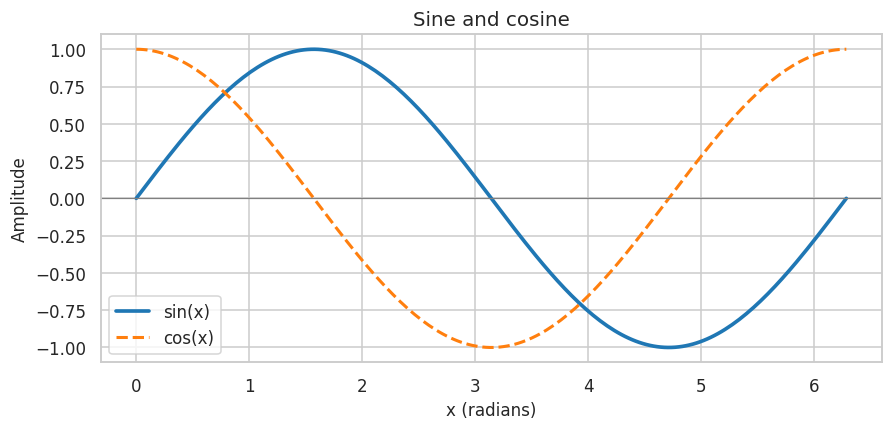

In [53]:
x = np.linspace(0, 2*np.pi, 200)
fig, ax = plt.subplots(figsize=(8, 3.8), constrained_layout=True)
ax.plot(x, np.sin(x), color="tab:blue", linewidth=2.4, label="sin(x)")
ax.plot(x, np.cos(x), color="tab:orange", linewidth=2.0, linestyle="--", label="cos(x)")
ax.set(title="Sine and cosine", xlabel="x (radians)", ylabel="Amplitude")
ax.axhline(0, color="gray", linewidth=.8)
ax.legend()
plt.show()
assert len(ax.lines) >= 3

### Lab 02 — Bar chart vs histogram

**Goal:** Compare categorical counts with a numeric distribution.

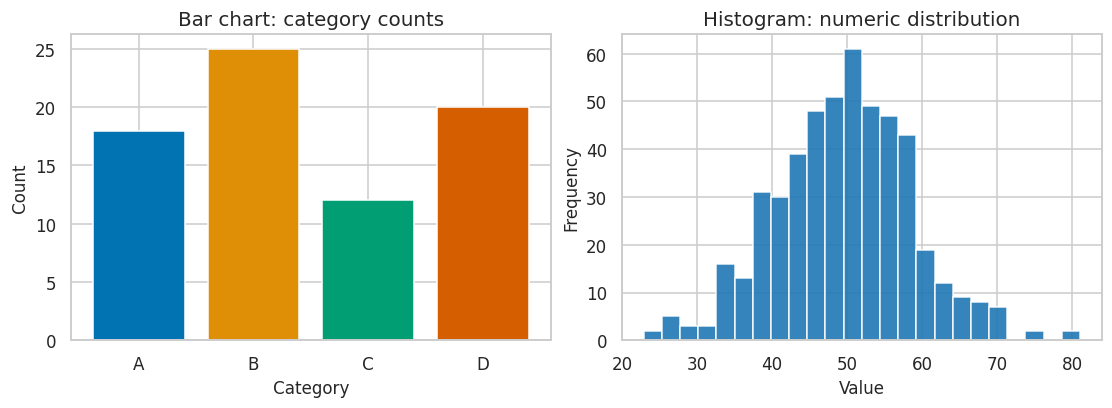

In [54]:
categories = ["A", "B", "C", "D"]
counts = [18, 25, 12, 20]
values = np.random.default_rng(1).normal(loc=50, scale=10, size=500)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), constrained_layout=True)
axes[0].bar(categories, counts, color=sns.color_palette("colorblind", 4))
axes[0].set(title="Bar chart: category counts", xlabel="Category", ylabel="Count")
axes[1].hist(values, bins=24, color="tab:blue", edgecolor="white", alpha=.9)
axes[1].set(title="Histogram: numeric distribution", xlabel="Value", ylabel="Frequency")
plt.show()
assert sum(counts) == 75

### Lab 03 — Histogram bin sensitivity

**Goal:** See why bins change the apparent distribution.

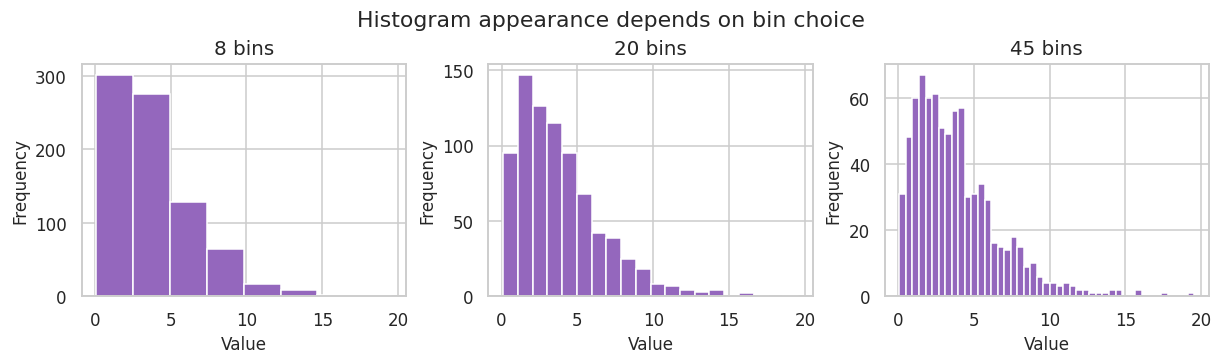

In [55]:
x = np.random.default_rng(2).gamma(shape=2.0, scale=2.0, size=800)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), constrained_layout=True)
for ax, bins in zip(axes, [8, 20, 45]):
    ax.hist(x, bins=bins, color="tab:purple", edgecolor="white")
    ax.set(title=f"{bins} bins", xlabel="Value", ylabel="Frequency")
fig.suptitle("Histogram appearance depends on bin choice")
plt.show()
assert len(x) == 800

### Lab 04 — KDE vs ECDF

**Goal:** Compare smoothed density with cumulative probability.

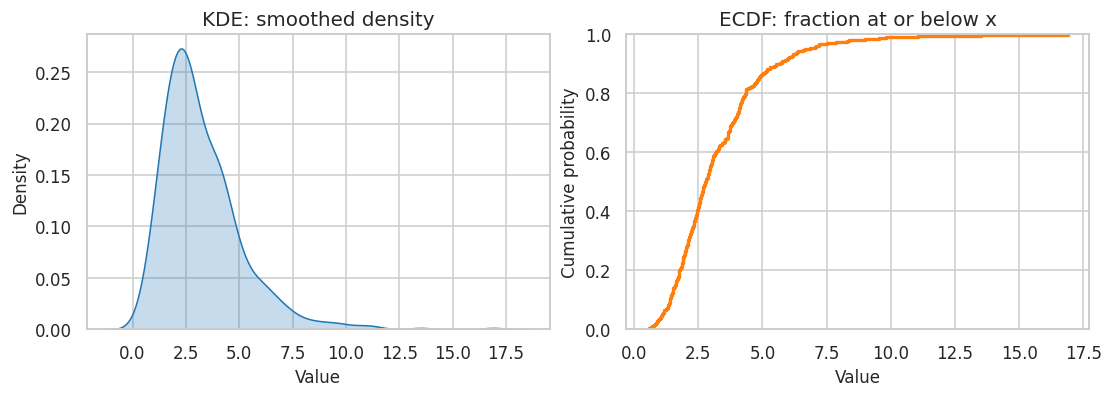

In [56]:
x = np.random.default_rng(3).lognormal(mean=1.0, sigma=.55, size=500)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
sns.kdeplot(x=x, fill=True, color="tab:blue", ax=axes[0])
axes[0].set(title="KDE: smoothed density", xlabel="Value", ylabel="Density")
sns.ecdfplot(x=x, color="tab:orange", linewidth=2.2, ax=axes[1])
axes[1].set(title="ECDF: fraction at or below x", xlabel="Value", ylabel="Cumulative probability")
plt.show()
assert np.all(x > 0)

### Lab 05 — Boxplot, violinplot, and points

**Goal:** Compare group spread and raw observations.

/tmp/ipykernel_429/2301757303.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x="group", y="score", ax=axes[1], inner="quartile", palette="Set2")


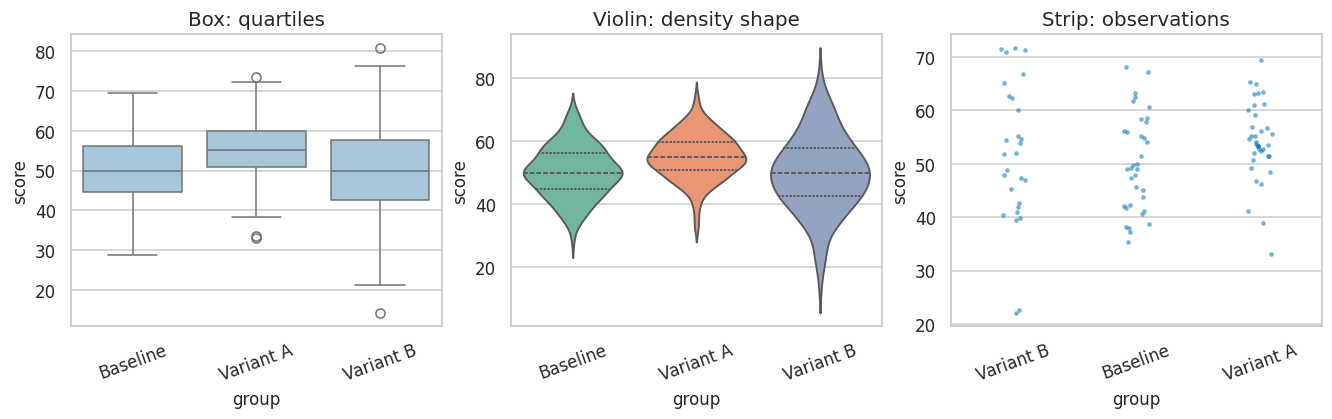

In [57]:
rng = np.random.default_rng(4)
df = pd.DataFrame({"group": np.repeat(["Baseline", "Variant A", "Variant B"], 150),
                   "score": np.r_[rng.normal(50, 8, 150), rng.normal(54, 7, 150), rng.normal(52, 12, 150)]})
fig, axes = plt.subplots(1, 3, figsize=(12, 3.7), constrained_layout=True)
sns.boxplot(data=df, x="group", y="score", ax=axes[0], color="#9ecae1")
sns.violinplot(data=df, x="group", y="score", ax=axes[1], inner="quartile", palette="Set2")
sns.stripplot(data=df.sample(100, random_state=4), x="group", y="score", ax=axes[2], alpha=.55, size=3)
for ax, title in zip(axes, ["Box: quartiles", "Violin: density shape", "Strip: observations"]):
    ax.set_title(title); ax.tick_params(axis="x", rotation=20)
plt.show()
assert len(df) == 450

### Lab 06 — Scatterplot and nonlinear relationship

**Goal:** Inspect paired values and avoid assuming linearity.

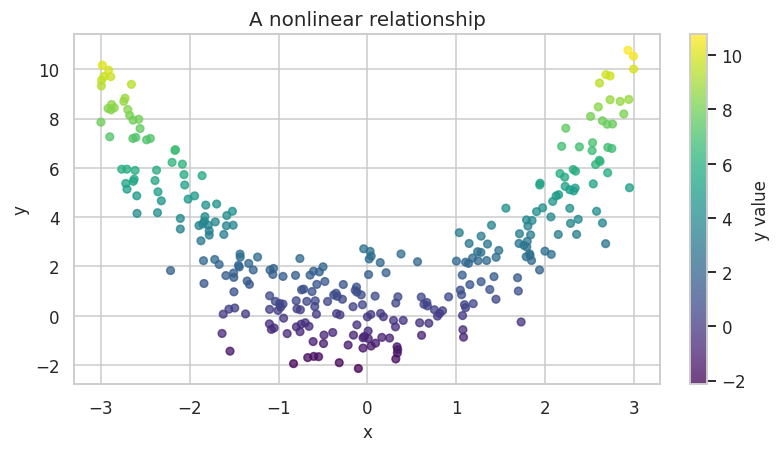

In [58]:
rng = np.random.default_rng(5)
x = rng.uniform(-3, 3, 300)
y = x**2 + rng.normal(0, 1.3, 300)
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
sc = ax.scatter(x, y, c=y, cmap="viridis", alpha=.75, s=25)
fig.colorbar(sc, ax=ax, label="y value")
ax.set(title="A nonlinear relationship", xlabel="x", ylabel="y")
plt.show()
assert len(x) == len(y)

### Lab 07 — Line plot with uncertainty band

**Goal:** Plot an ordered trend and clearly labelled uncertainty.

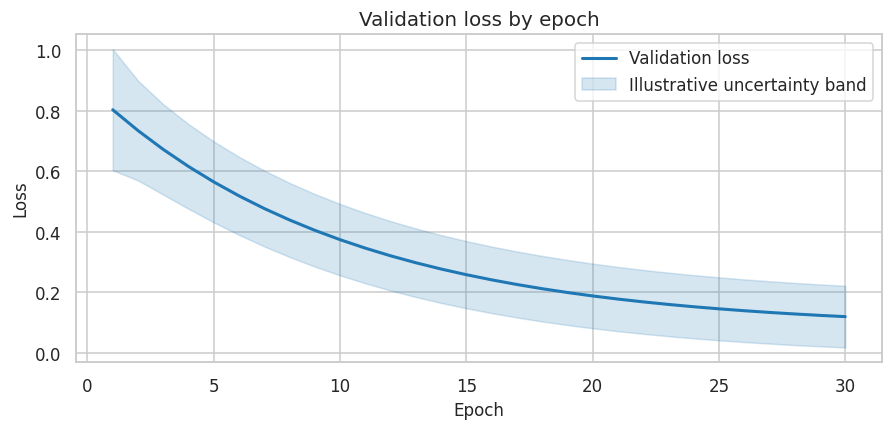

In [59]:
t = np.arange(1, 31)
mean = 0.8*np.exp(-t/10) + .08
uncertainty = .08 + .12/np.sqrt(t)
fig, ax = plt.subplots(figsize=(8, 3.8), constrained_layout=True)
ax.plot(t, mean, color="tab:blue", linewidth=2, label="Validation loss")
ax.fill_between(t, mean-uncertainty, mean+uncertainty, color="tab:blue", alpha=.18, label="Illustrative uncertainty band")
ax.set(title="Validation loss by epoch", xlabel="Epoch", ylabel="Loss")
ax.legend()
plt.show()
assert len(t) == 30

### Lab 08 — Heatmap and diverging palette

**Goal:** Use a diverging palette for correlations centered on zero.

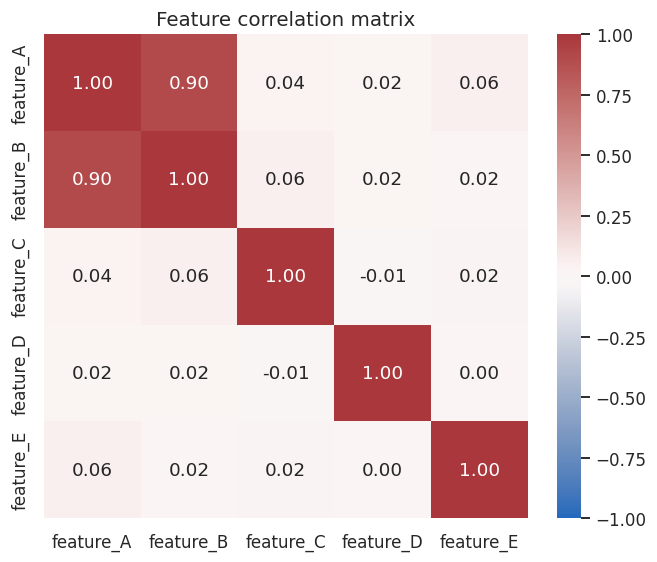

In [60]:
rng = np.random.default_rng(6)
data = rng.normal(size=(300, 5))
data[:, 1] = .8*data[:, 0] + .4*rng.normal(size=300)
corr = pd.DataFrame(data, columns=["feature_A","feature_B","feature_C","feature_D","feature_E"]).corr()
fig, ax = plt.subplots(figsize=(6.5, 5), constrained_layout=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Feature correlation matrix")
plt.show()
assert corr.shape == (5, 5)

### Lab 09 — Pairplot for small feature sets

**Goal:** Use pair plots only when the number of variables is manageable.

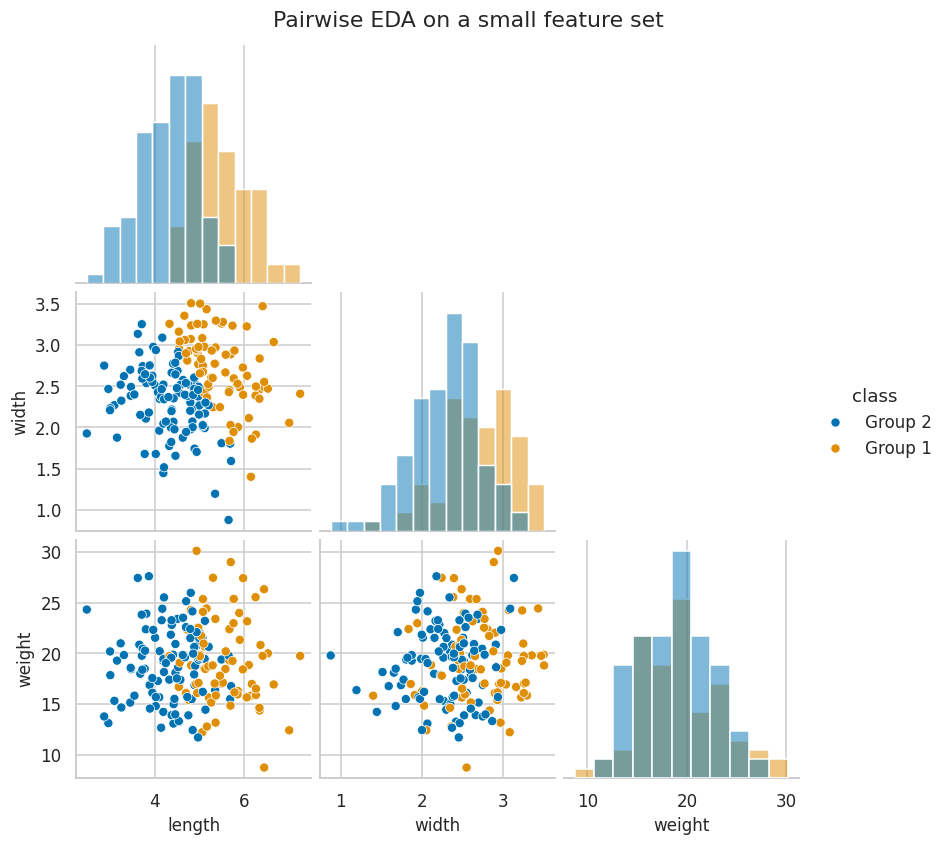

In [61]:
rng = np.random.default_rng(7)
df = pd.DataFrame({"length": rng.normal(5, 1, 180),
                   "width": rng.normal(2.5, .5, 180),
                   "weight": rng.normal(20, 4, 180)})
df["class"] = np.where(df["length"] + df["width"] > 7.5, "Group 1", "Group 2")
g = sns.pairplot(df, vars=["length", "width", "weight"], hue="class", corner=True, diag_kind="hist")
g.fig.suptitle("Pairwise EDA on a small feature set", y=1.02)
plt.show()
assert df.shape[0] == 180

### Lab 10 — Faceting with small multiples

**Goal:** Compare the same relationship across groups.

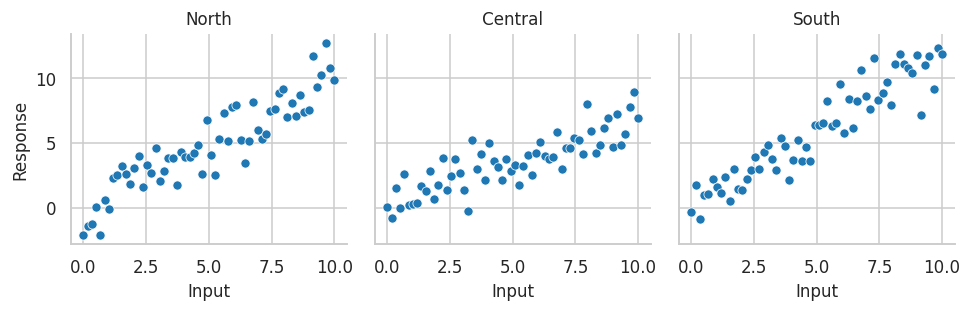

In [62]:
rng = np.random.default_rng(8)
df = pd.DataFrame({"x": np.tile(np.linspace(0, 10, 60), 3),
                   "group": np.repeat(["North", "Central", "South"], 60)})
df["y"] = df["x"] * df["group"].map({"North":1.0,"Central":.7,"South":1.2}) + rng.normal(0, 1.2, len(df))
g = sns.relplot(data=df, x="x", y="y", col="group", kind="scatter", height=3, aspect=1, color="tab:blue")
g.set_axis_labels("Input", "Response")
g.set_titles("{col_name}")
plt.show()
assert df["group"].nunique() == 3

### Lab 11 — Countplot vs barplot

**Goal:** Distinguish counting rows from estimating a numeric summary.

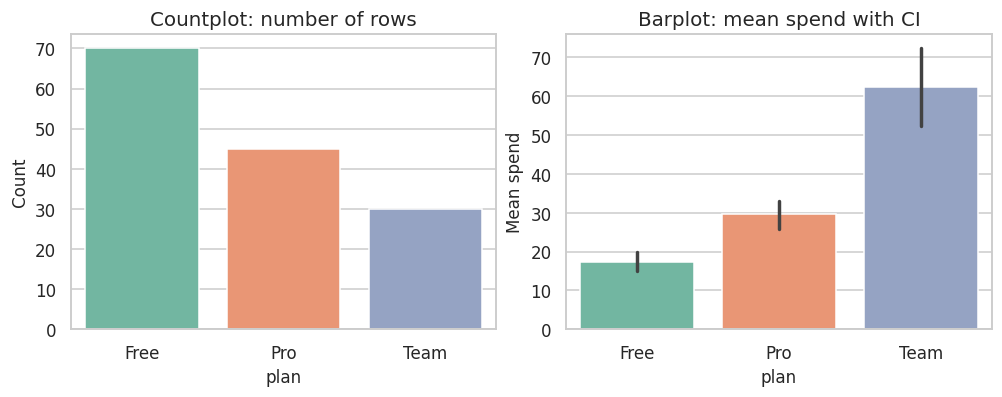

In [63]:
df = pd.DataFrame({"plan": np.repeat(["Free","Pro","Team"], [70,45,30]),
                   "spend": np.r_[np.random.default_rng(9).gamma(2,10,70),
                                  np.random.default_rng(10).gamma(3,12,45),
                                  np.random.default_rng(11).gamma(4,15,30)]})
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), constrained_layout=True)
sns.countplot(data=df, x="plan", hue="plan", legend=False, ax=axes[0], palette="Set2")
sns.barplot(data=df, x="plan", y="spend", hue="plan", legend=False, ax=axes[1], palette="Set2", errorbar=("ci", 95))
axes[0].set(title="Countplot: number of rows", ylabel="Count")
axes[1].set(title="Barplot: mean spend with CI", ylabel="Mean spend")
plt.show()
assert len(df) == 145

### Lab 12 — Residual diagnostics

**Goal:** Use multiple diagnostics rather than a single residual histogram.

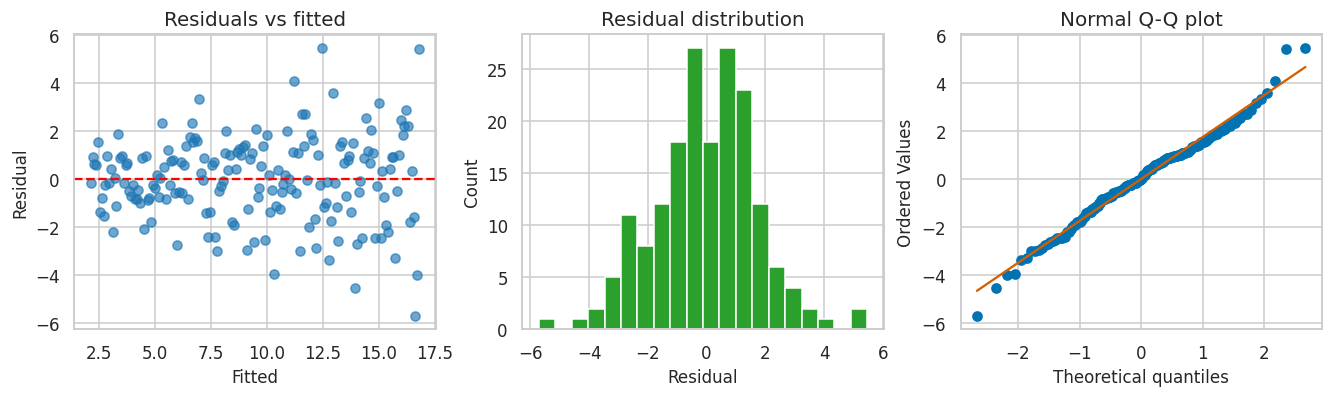

In [64]:
rng = np.random.default_rng(12)
x = np.linspace(0, 10, 180)
y = 2 + 1.5*x + rng.normal(0, 1 + .15*x, size=len(x))
coef = np.polyfit(x, y, 1)
pred = np.polyval(coef, x)
resid = y-pred
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), constrained_layout=True)
axes[0].scatter(pred, resid, alpha=.65, color="tab:blue")
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set(title="Residuals vs fitted", xlabel="Fitted", ylabel="Residual")
axes[1].hist(resid, bins=20, color="tab:green", edgecolor="white")
axes[1].set(title="Residual distribution", xlabel="Residual", ylabel="Count")
stats.probplot(resid, dist="norm", plot=axes[2])
axes[2].set_title("Normal Q-Q plot")
plt.show()
assert len(resid) == len(y)

### Lab 13 — Confusion matrix heatmap

**Goal:** Label the class names and make the normalization choice explicit.

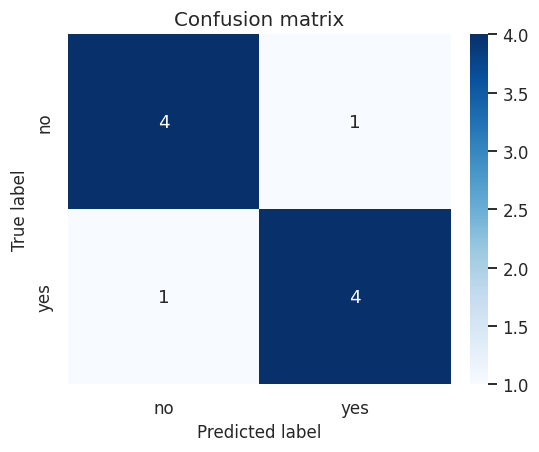

In [65]:
from sklearn.metrics import confusion_matrix
y_true = ["no","yes","yes","no","yes","no","yes","no","no","yes"]
y_pred = ["no","yes","no","no","yes","yes","yes","no","no","yes"]
cm = confusion_matrix(y_true, y_pred, labels=["no","yes"])
fig, ax = plt.subplots(figsize=(4.8, 4), constrained_layout=True)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["no","yes"], yticklabels=["no","yes"], ax=ax)
ax.set(title="Confusion matrix", xlabel="Predicted label", ylabel="True label")
plt.show()
assert cm.sum() == len(y_true)

### Lab 14 — ROC and precision-recall curves

**Goal:** Use ROC for ranking overview and PR when positives are rare.

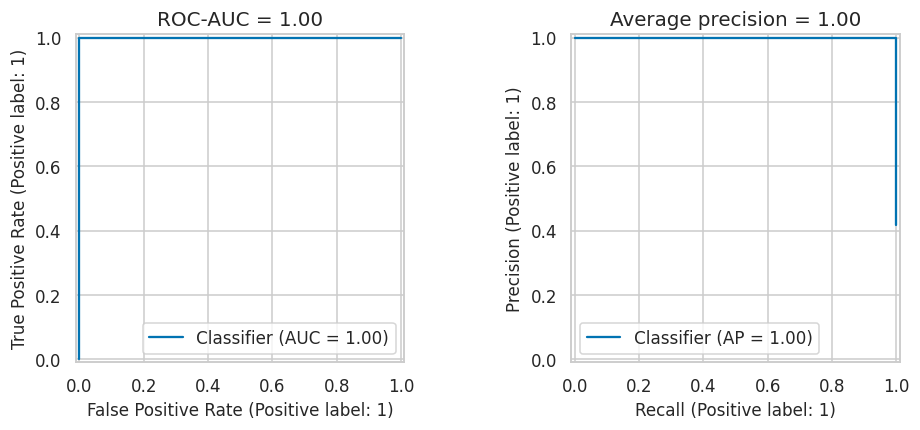

In [66]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, roc_auc_score, average_precision_score
y = np.array([0,0,0,1,0,1,0,1,1,0,1,0])
score = np.array([.05,.15,.30,.82,.20,.73,.10,.91,.66,.28,.78,.40])
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), constrained_layout=True)
RocCurveDisplay.from_predictions(y, score, ax=axes[0], name="Classifier")
PrecisionRecallDisplay.from_predictions(y, score, ax=axes[1], name="Classifier")
axes[0].set_title(f"ROC-AUC = {roc_auc_score(y, score):.2f}")
axes[1].set_title(f"Average precision = {average_precision_score(y, score):.2f}")
plt.show()
assert roc_auc_score(y, score) > .5

### Lab 15 — Calibration curve

**Goal:** Check whether predicted probabilities agree with observed event rates.

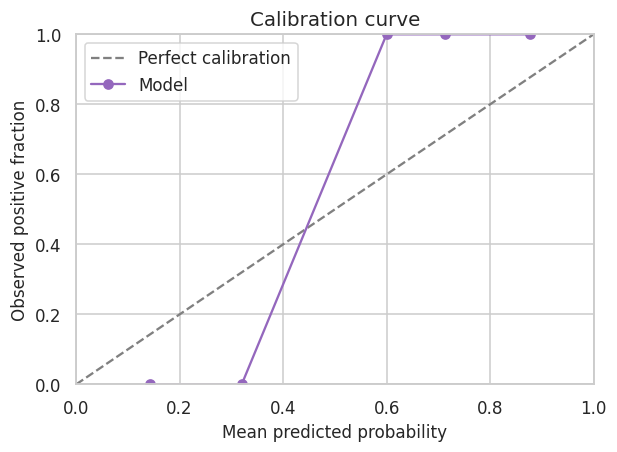

In [67]:
from sklearn.calibration import calibration_curve
y = np.array([0,1,0,1,1,0,1,0,0,1,1,0,1,0,1,0,1,0,1,0])
p = np.array([.1,.8,.2,.7,.65,.35,.9,.3,.25,.75,.6,.4,.85,.15,.72,.28,.66,.34,.88,.12])
frac_pos, mean_pred = calibration_curve(y, p, n_bins=5, strategy="uniform")
fig, ax = plt.subplots(figsize=(5.5, 4), constrained_layout=True)
ax.plot([0,1], [0,1], linestyle="--", color="gray", label="Perfect calibration")
ax.plot(mean_pred, frac_pos, marker="o", color="tab:purple", label="Model")
ax.set(xlim=(0,1), ylim=(0,1), title="Calibration curve", xlabel="Mean predicted probability", ylabel="Observed positive fraction")
ax.legend()
plt.show()
assert len(frac_pos) > 0

### Lab 16 — SciPy PDF, CDF, PPF, and survival function

**Goal:** Calculate probabilities and quantiles from a normal distribution.

In [68]:
mu, sigma = 10, 2
dist = stats.norm(loc=mu, scale=sigma)
x = 13
print("PDF at x (density, not point probability):", round(dist.pdf(x), 4))
print("P(X <= 13):", round(dist.cdf(x), 4))
print("95th percentile:", round(dist.ppf(.95), 4))
print("P(X > 13) via survival function:", round(dist.sf(x), 4))
assert np.isclose(dist.cdf(x) + dist.sf(x), 1)

PDF at x (density, not point probability): 0.0648
P(X <= 13): 0.9332
95th percentile: 13.2897
P(X > 13) via survival function: 0.0668


### Lab 17 — Normal distribution and z-score

**Goal:** Standardize a value and calculate a tail probability.

z-score: 1.6 upper-tail probability under normal model: 0.0548


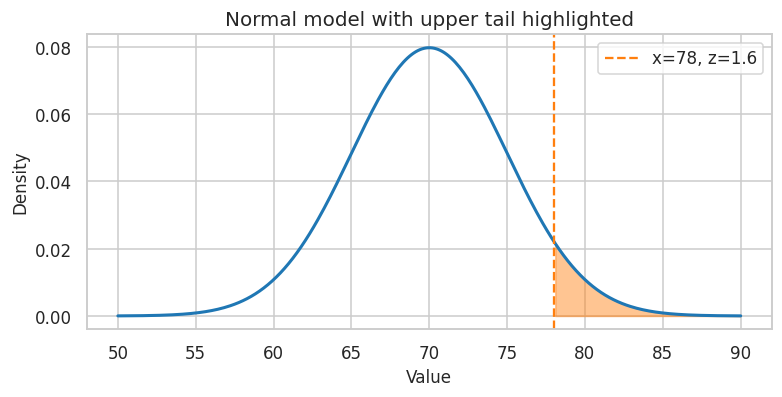

In [69]:
x, mu, sigma = 78, 70, 5
z = (x-mu)/sigma
tail_probability = stats.norm.sf(z)
print("z-score:", z, "upper-tail probability under normal model:", round(tail_probability, 5))
grid = np.linspace(mu-4*sigma, mu+4*sigma, 300)
fig, ax = plt.subplots(figsize=(7, 3.5), constrained_layout=True)
ax.plot(grid, stats.norm.pdf(grid, mu, sigma), color="tab:blue", linewidth=2)
ax.fill_between(grid, stats.norm.pdf(grid, mu, sigma), where=grid>=x, color="tab:orange", alpha=.45)
ax.axvline(x, color="tab:orange", linestyle="--", label=f"x={x}, z={z:.1f}")
ax.set(title="Normal model with upper tail highlighted", xlabel="Value", ylabel="Density")
ax.legend()
plt.show()
assert z == 1.6

### Lab 18 — Binomial distribution

**Goal:** Model a fixed number of independent binary trials.

Mean: 3.0 Variance: 2.55 P(X >= 5): 0.1702


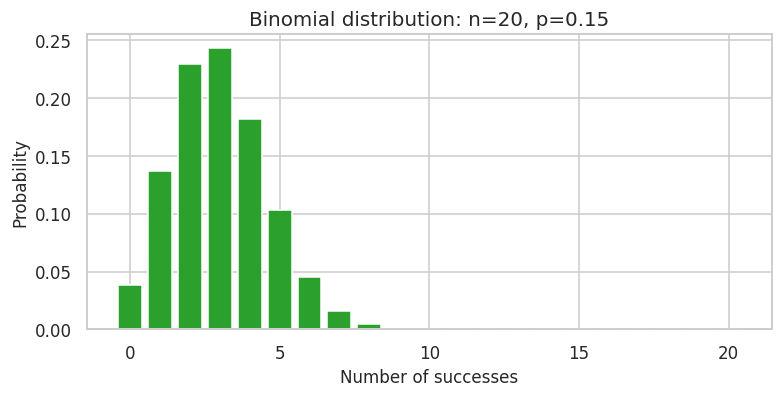

In [70]:
n, p = 20, .15
dist = stats.binom(n=n, p=p)
k = np.arange(0, n+1)
fig, ax = plt.subplots(figsize=(7, 3.5), constrained_layout=True)
ax.bar(k, dist.pmf(k), color="tab:green", edgecolor="white")
ax.set(title="Binomial distribution: n=20, p=0.15", xlabel="Number of successes", ylabel="Probability")
print("Mean:", dist.mean(), "Variance:", dist.var(), "P(X >= 5):", round(dist.sf(4), 4))
plt.show()
assert np.isclose(dist.mean(), n*p)

### Lab 19 — Poisson distribution

**Goal:** Model counts under a fixed exposure and rate.

Mean: 4.0 Variance: 4.0 P(X > 7): 0.0511


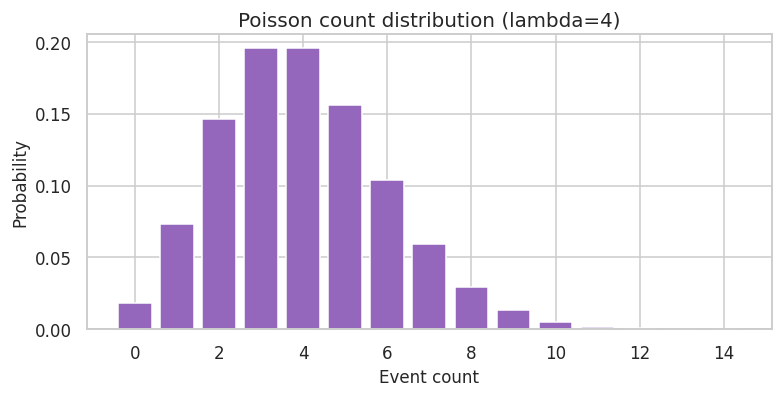

In [71]:
lam = 4
dist = stats.poisson(mu=lam)
k = np.arange(0, 15)
fig, ax = plt.subplots(figsize=(7, 3.5), constrained_layout=True)
ax.bar(k, dist.pmf(k), color="tab:purple", edgecolor="white")
ax.set(title="Poisson count distribution (lambda=4)", xlabel="Event count", ylabel="Probability")
print("Mean:", dist.mean(), "Variance:", dist.var(), "P(X > 7):", round(dist.sf(7), 4))
plt.show()
assert dist.mean() == dist.var() == lam

### Lab 20 — Welch t-test with effect size

**Goal:** Compare independent means without assuming equal variances.

In [72]:
a = np.array([10, 11, 9, 12, 10, 11], dtype=float)
b = np.array([13, 15, 14, 12, 16, 14, 15], dtype=float)
res = stats.ttest_ind(a, b, equal_var=False)
difference = b.mean()-a.mean()
print("mean difference (B-A):", round(difference, 3))
print("Welch t:", round(res.statistic, 3), "p-value:", round(res.pvalue, 5))
assert 0 <= res.pvalue <= 1

mean difference (B-A): 3.643
Welch t: -5.48 p-value: 0.0002


### Lab 21 — Paired t-test

**Goal:** Use pairing when each before observation matches an after observation.

In [73]:
before = np.array([20,22,19,24,21,23,20,22], dtype=float)
after  = np.array([18,21,17,22,20,20,19,20], dtype=float)
res = stats.ttest_rel(after, before)
print("mean change after-before:", round((after-before).mean(), 3))
print("paired t:", round(res.statistic, 3), "p-value:", round(res.pvalue, 5))
assert len(before) == len(after)

mean change after-before: -1.75
paired t: -7.0 p-value: 0.00021


### Lab 22 — Pearson vs Spearman correlation

**Goal:** Compare linear correlation with rank-based monotonic association.

In [74]:
x = np.arange(1, 11, dtype=float)
y = x**2 + np.array([0,2,-1,1,0,-2,1,0,2,-1])
pearson = stats.pearsonr(x, y)
spearman = stats.spearmanr(x, y)
print("Pearson r:", round(pearson.statistic, 3), "p:", round(pearson.pvalue, 5))
print("Spearman rho:", round(spearman.statistic, 3), "p:", round(spearman.pvalue, 5))
assert spearman.statistic > .9

Pearson r: 0.973 p: 0.0
Spearman rho: 1.0 p: 0.0


### Lab 23 — Chi-square test for categorical association

**Goal:** Test association in a contingency table and inspect expected counts.

In [75]:
table = np.array([[42, 18], [25, 35]])
chi2, p, dof, expected = stats.chi2_contingency(table)
print("chi-square:", round(chi2, 3), "p-value:", round(p, 5), "dof:", dof)
print("Expected counts:\n", expected)
assert expected.shape == table.shape

chi-square: 8.651 p-value: 0.00327 dof: 1
Expected counts:
 [[33.5 26.5]
 [33.5 26.5]]


### Lab 24 — Bootstrap confidence interval with SciPy

**Goal:** Estimate uncertainty using resampling rather than a simple parametric formula.

In [76]:
data = np.array([3,4,5,5,6,7,9,10], dtype=float)
result = stats.bootstrap((data,), np.mean, confidence_level=.95, n_resamples=3000, method="BCa", random_state=42)
print("mean:", round(data.mean(), 3))
print("95% bootstrap CI:", tuple(np.round([result.confidence_interval.low, result.confidence_interval.high], 3)))
assert result.confidence_interval.low < result.confidence_interval.high

mean: 6.125
95% bootstrap CI: (np.float64(4.75), np.float64(7.875))


### Lab 25 — Permutation test for a difference in means

**Goal:** Build a null distribution by shuffling group labels under exchangeability.

observed difference: 2.8 permutation p-value: 0.017


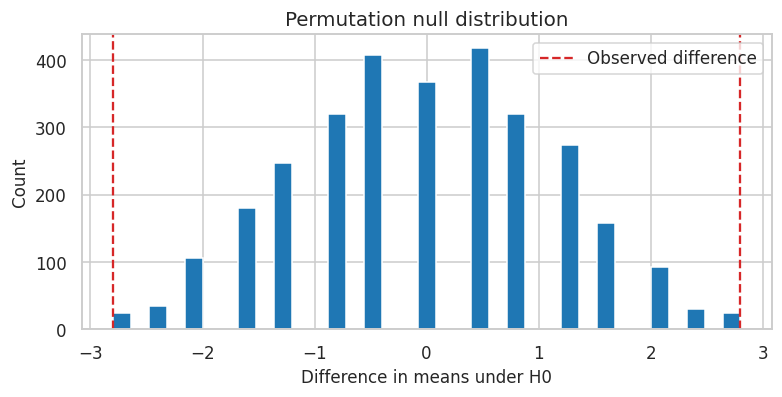

In [77]:
rng = np.random.default_rng(21)
a = np.array([4,5,6,5,4], dtype=float)
b = np.array([7,8,6,9,8], dtype=float)
observed = b.mean()-a.mean()
pooled = np.r_[a,b]
null = []
for _ in range(3000):
    perm = rng.permutation(pooled)
    null.append(perm[len(a):].mean()-perm[:len(a)].mean())
null = np.asarray(null)
pvalue = (np.sum(np.abs(null) >= abs(observed))+1)/(len(null)+1)
print("observed difference:", observed, "permutation p-value:", round(pvalue, 4))
fig, ax = plt.subplots(figsize=(7, 3.5), constrained_layout=True)
ax.hist(null, bins=35, color="tab:blue", edgecolor="white")
ax.axvline(observed, color="tab:red", linestyle="--", label="Observed difference")
ax.axvline(-observed, color="tab:red", linestyle="--")
ax.set(title="Permutation null distribution", xlabel="Difference in means under H0", ylabel="Count")
ax.legend()
plt.show()
assert 0 <= pvalue <= 1

### Lab 26 — Multiple testing: Bonferroni and Benjamini-Hochberg

**Goal:** Compare family-wise error control with false-discovery-rate control.

In [78]:
pvals = np.array([.001, .008, .018, .04, .21])
alpha = .05
bonf = pvals < alpha/len(pvals)
m = len(pvals); order = np.argsort(pvals); ranked = pvals[order]
thresholds = alpha*np.arange(1, m+1)/m
eligible = np.where(ranked <= thresholds)[0]
bh = np.zeros(m, dtype=bool)
if len(eligible):
    bh[order[:eligible.max()+1]] = True
print("Bonferroni reject:", bonf.tolist())
print("Benjamini-Hochberg reject:", bh.tolist())
assert bonf.sum() <= bh.sum()

Bonferroni reject: [True, True, False, False, False]
Benjamini-Hochberg reject: [True, True, True, True, False]


### Lab 27 — Optimization: fit a nonlinear curve

**Goal:** Use SciPy curve_fit to estimate parameters of a model from data.

estimated [a,b,c]: [2.889 0.778 0.526]


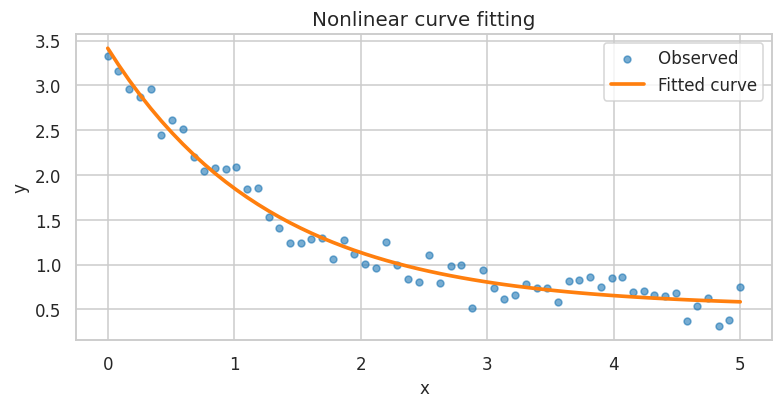

In [79]:
def model(x, a, b, c):
    return a*np.exp(-b*x)+c
rng = np.random.default_rng(22)
x = np.linspace(0, 5, 60)
y = model(x, 3.0, .8, .5) + rng.normal(0, .12, len(x))
params, covariance = optimize.curve_fit(model, x, y, p0=[2, .5, .3], maxfev=10000)
print("estimated [a,b,c]:", np.round(params, 3))
fig, ax = plt.subplots(figsize=(7, 3.6), constrained_layout=True)
ax.scatter(x, y, s=20, alpha=.6, label="Observed", color="tab:blue")
ax.plot(x, model(x, *params), color="tab:orange", linewidth=2.4, label="Fitted curve")
ax.set(title="Nonlinear curve fitting", xlabel="x", ylabel="y")
ax.legend()
plt.show()
assert np.all(np.isfinite(params))

### Lab 28 — Numerical integration with SciPy

**Goal:** Approximate an integral and compare against a known result.

In [80]:
value, error = integrate.quad(lambda x: np.exp(-x*x), 0, 1)
print("Integral of exp(-x^2) from 0 to 1:", round(value, 8))
print("Estimated absolute integration error:", error)
assert 0 < value < 1

Integral of exp(-x^2) from 0 to 1: 0.74682413
Estimated absolute integration error: 8.291413475940725e-15


### Lab 29 — Solve a linear system with SciPy

**Goal:** Solve Ax=b without explicitly computing an inverse.

In [81]:
A = np.array([[3., 1.], [1., 2.]])
b = np.array([9., 8.])
x = linalg.solve(A, b)
print("solution:", x)
print("residual:", A@x-b)
assert np.allclose(A@x, b)

solution: [2. 3.]
residual: [0. 0.]


### Lab 30 — Distribution comparison with ECDF

**Goal:** Compare distributions using the empirical CDF and a two-sample KS test.

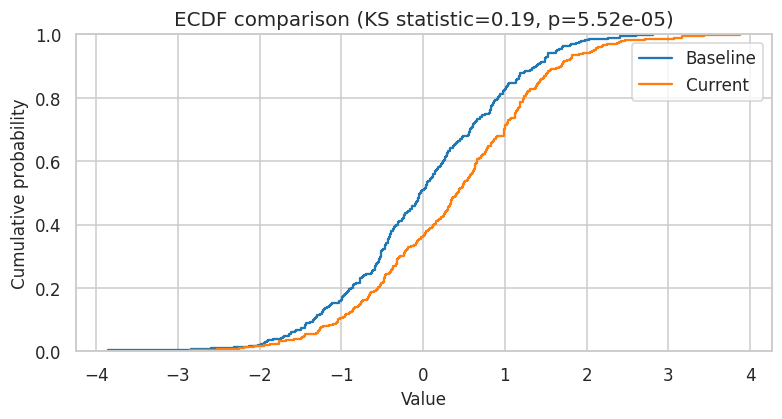

KS statistic: 0.187 p-value: 6e-05


In [82]:
rng = np.random.default_rng(23)
baseline = rng.normal(0, 1, 300)
current = rng.normal(.35, 1.1, 300)
res = stats.ks_2samp(baseline, current)
fig, ax = plt.subplots(figsize=(7, 3.7), constrained_layout=True)
sns.ecdfplot(x=baseline, ax=ax, label="Baseline", color="tab:blue")
sns.ecdfplot(x=current, ax=ax, label="Current", color="tab:orange")
ax.set(title=f"ECDF comparison (KS statistic={res.statistic:.2f}, p={res.pvalue:.3g})", xlabel="Value", ylabel="Cumulative probability")
ax.legend()
plt.show()
print("KS statistic:", round(res.statistic, 3), "p-value:", round(res.pvalue, 5))
assert 0 <= res.pvalue <= 1

### Lab 31 — Visualize missingness

**Goal:** Show missingness rates and compare them across columns.

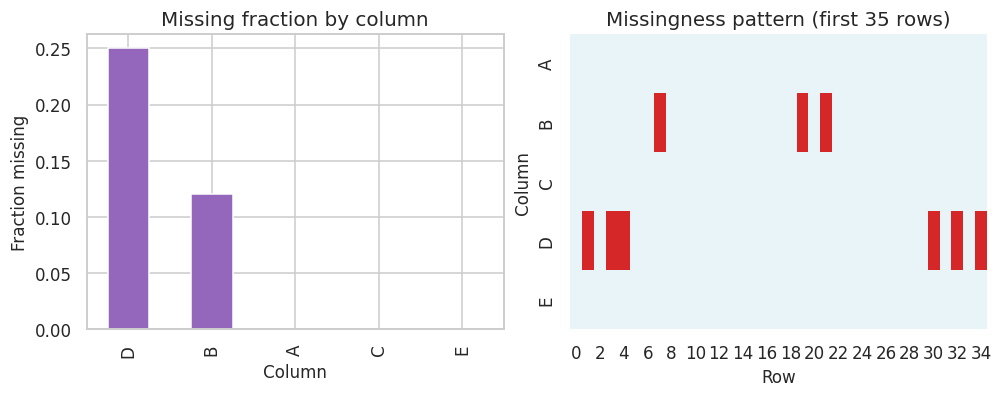

In [83]:
rng = np.random.default_rng(24)
df = pd.DataFrame(rng.normal(size=(100, 5)), columns=list("ABCDE"))
df.loc[rng.choice(df.index, 12, replace=False), "B"] = np.nan
df.loc[rng.choice(df.index, 25, replace=False), "D"] = np.nan
missing = df.isna().mean().sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), constrained_layout=True)
missing.plot(kind="bar", ax=axes[0], color="tab:purple")
axes[0].set(title="Missing fraction by column", ylabel="Fraction missing", xlabel="Column")
sns.heatmap(df.isna().iloc[:35].T, cmap=sns.color_palette(["#e8f4f8", "#d62728"]), cbar=False, ax=axes[1])
axes[1].set(title="Missingness pattern (first 35 rows)", xlabel="Row", ylabel="Column")
plt.show()
assert missing["D"] > missing["A"]

### Lab 32 — Compare group distributions with ECDFs

**Goal:** Use ECDFs when percentile and tail comparisons matter.

Group A p95: 11.47 Group B p95: 16.74


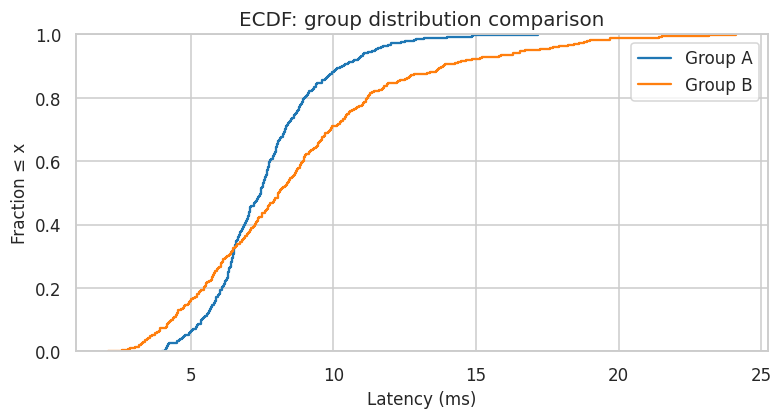

In [84]:
rng = np.random.default_rng(25)
a = rng.lognormal(2.0, .25, 400)
b = rng.lognormal(2.05, .45, 400)
fig, ax = plt.subplots(figsize=(7, 3.7), constrained_layout=True)
sns.ecdfplot(x=a, ax=ax, label="Group A", color="tab:blue")
sns.ecdfplot(x=b, ax=ax, label="Group B", color="tab:orange")
ax.set(title="ECDF: group distribution comparison", xlabel="Latency (ms)", ylabel="Fraction ≤ x")
ax.legend()
print("Group A p95:", round(np.quantile(a, .95), 2), "Group B p95:", round(np.quantile(b, .95), 2))
plt.show()
assert np.quantile(a, .95) > 0

### Lab 33 — Visualize uncertainty in group means

**Goal:** Show confidence intervals for means and label them explicitly.

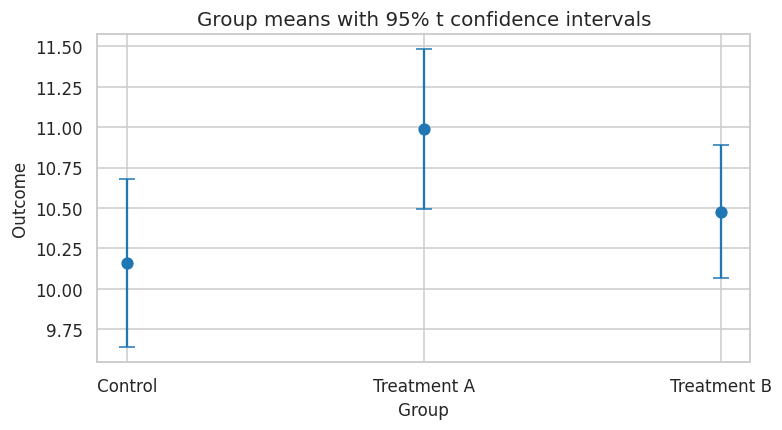

In [85]:
rng = np.random.default_rng(26)
groups = {"Control": rng.normal(10, 2, 80), "Treatment A": rng.normal(11, 2.2, 80), "Treatment B": rng.normal(10.6, 1.8, 80)}
names, means, lows, highs = [], [], [], []
for name, values in groups.items():
    se = stats.sem(values)
    ci = stats.t.interval(.95, df=len(values)-1, loc=np.mean(values), scale=se)
    names.append(name); means.append(np.mean(values)); lows.append(means[-1]-ci[0]); highs.append(ci[1]-means[-1])
fig, ax = plt.subplots(figsize=(7, 3.8), constrained_layout=True)
ax.errorbar(names, means, yerr=[lows, highs], fmt="o", capsize=5, color="tab:blue", markersize=7)
ax.set(title="Group means with 95% t confidence intervals", xlabel="Group", ylabel="Outcome")
plt.show()
assert len(means) == 3

### Lab 34 — Log scale for skewed positive data

**Goal:** Use a log axis when values span orders of magnitude and are positive.

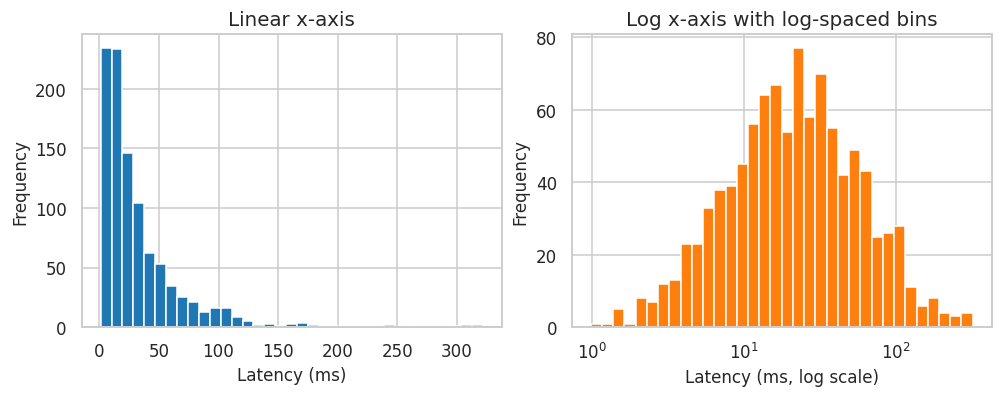

In [86]:
rng = np.random.default_rng(27)
latency = rng.lognormal(mean=3.0, sigma=1.0, size=1000)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), constrained_layout=True)
axes[0].hist(latency, bins=35, color="tab:blue", edgecolor="white")
axes[0].set(title="Linear x-axis", xlabel="Latency (ms)", ylabel="Frequency")
axes[1].hist(latency, bins=np.logspace(np.log10(latency.min()), np.log10(latency.max()), 35), color="tab:orange", edgecolor="white")
axes[1].set_xscale("log")
axes[1].set(title="Log x-axis with log-spaced bins", xlabel="Latency (ms, log scale)", ylabel="Frequency")
plt.show()
assert np.all(latency > 0)

### Lab 35 — Numerical stability: survival function vs 1-CDF

**Goal:** Use survival functions for more stable upper-tail probabilities.

In [87]:
z = 8
print("1 - CDF:", stats.norm.sf(z), "direct SF:", stats.norm.sf(z))
print("log survival:", stats.norm.logsf(z))
assert stats.norm.sf(z) > 0

1 - CDF: 6.22096057427174e-16 direct SF: 6.22096057427174e-16
log survival: -35.01343715991456


### Lab 36 — SciPy root finding

**Goal:** Solve an equation by finding a root of f(x).

In [88]:
root = optimize.brentq(lambda x: x**3 - 2*x - 5, 2, 3)
print("root:", root, "function at root:", root**3 - 2*root - 5)
assert abs(root**3 - 2*root - 5) < 1e-8

root: 2.094551481542327 function at root: 3.552713678800501e-15


### Lab 37 — Signal smoothing with SciPy

**Goal:** Use a simple filter to smooth noisy ordered measurements.

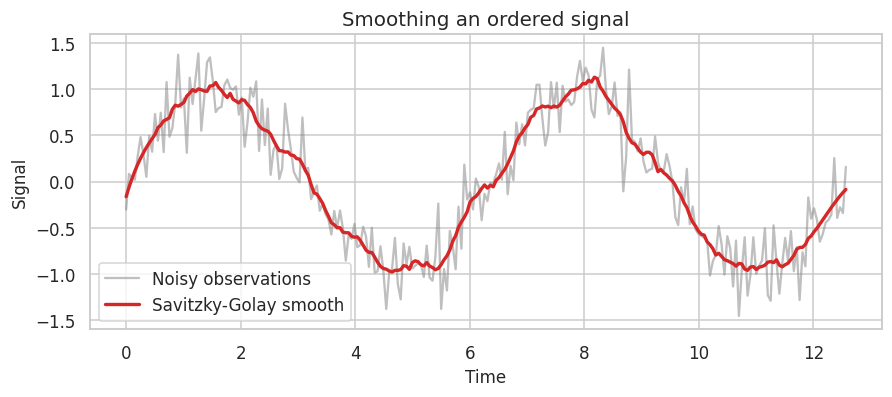

In [89]:
from scipy.signal import savgol_filter
rng = np.random.default_rng(28)
t = np.linspace(0, 4*np.pi, 250)
signal = np.sin(t) + rng.normal(0, .25, len(t))
smooth = savgol_filter(signal, window_length=21, polyorder=3)
fig, ax = plt.subplots(figsize=(8, 3.5), constrained_layout=True)
ax.plot(t, signal, color="gray", alpha=.5, label="Noisy observations")
ax.plot(t, smooth, color="tab:red", linewidth=2.2, label="Savitzky-Golay smooth")
ax.set(title="Smoothing an ordered signal", xlabel="Time", ylabel="Signal")
ax.legend()
plt.show()
assert len(smooth) == len(signal)

### Lab 38 — Pairwise plot with robust context

**Goal:** Use selected features, and sample when full pair plots are too large.

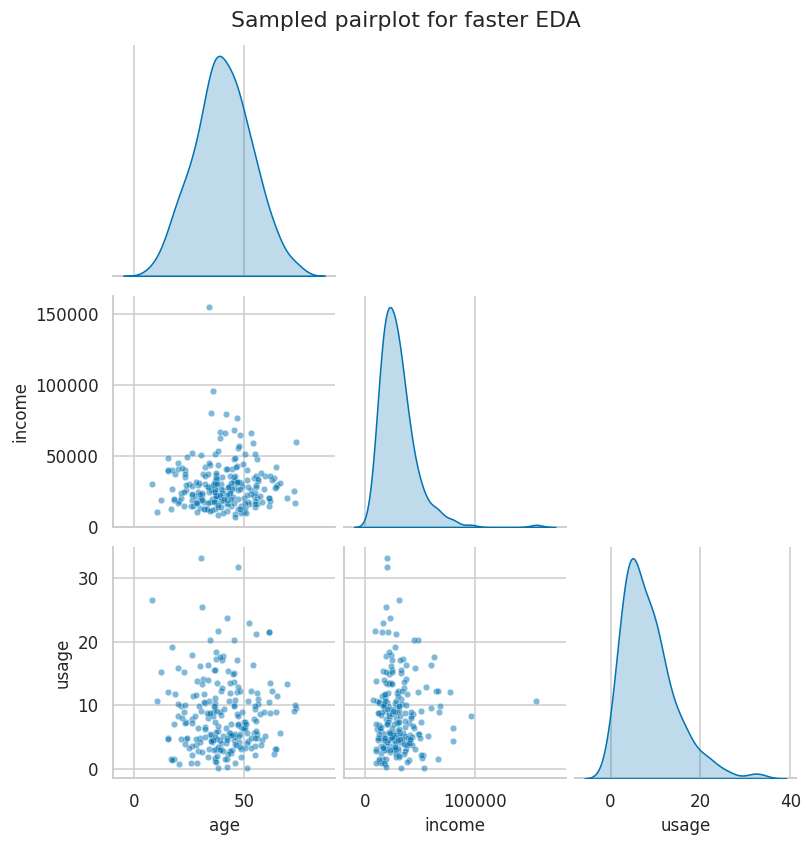

In [90]:
rng = np.random.default_rng(29)
df = pd.DataFrame({"age": rng.normal(40, 12, 600), "income": rng.lognormal(10.2, .5, 600), "usage": rng.gamma(2, 4, 600)})
sample = df.sample(220, random_state=29)
g = sns.pairplot(sample, corner=True, diag_kind="kde", plot_kws={"alpha": .5, "s": 18})
g.fig.suptitle("Sampled pairplot for faster EDA", y=1.02)
plt.show()
assert len(sample) == 220

### Lab 39 — Effect of outliers on mean and median

**Goal:** Use robust summaries to understand the influence of extreme values.

mean: 23.375 median: 12.5 IQR: 2.5


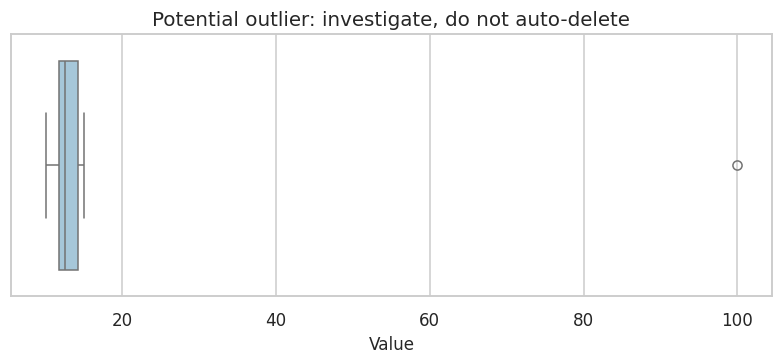

In [91]:
x = np.array([10, 11, 12, 12, 13, 14, 15, 100], dtype=float)
print("mean:", x.mean(), "median:", np.median(x), "IQR:", np.quantile(x,.75)-np.quantile(x,.25))
fig, ax = plt.subplots(figsize=(7, 3.2), constrained_layout=True)
sns.boxplot(x=x, ax=ax, color="#9ecae1")
ax.set(title="Potential outlier: investigate, do not auto-delete", xlabel="Value")
plt.show()
assert x.mean() > np.median(x)

### Lab 40 — Compare observed distribution with a theoretical normal

**Goal:** Overlay a fitted normal density as a diagnostic, not proof of normality.

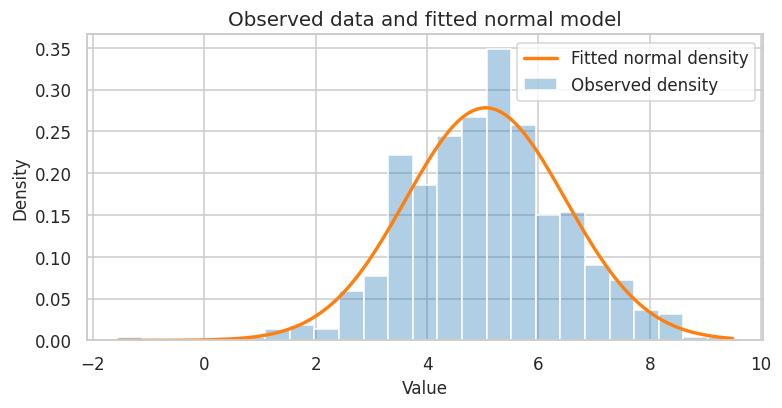

In [92]:
rng = np.random.default_rng(30)
x = rng.normal(5, 1.4, 500)
mu, sigma = x.mean(), x.std(ddof=1)
grid = np.linspace(x.min(), x.max(), 250)
fig, ax = plt.subplots(figsize=(7, 3.6), constrained_layout=True)
sns.histplot(x=x, stat="density", bins=25, color="tab:blue", alpha=.35, ax=ax, label="Observed density")
ax.plot(grid, stats.norm.pdf(grid, mu, sigma), color="tab:orange", linewidth=2.2, label="Fitted normal density")
ax.set(title="Observed data and fitted normal model", xlabel="Value", ylabel="Density")
ax.legend()
plt.show()
assert sigma > 0

### Lab 41 — Plot p-values with multiple-testing threshold

**Goal:** Visualize which hypotheses pass a corrected threshold.

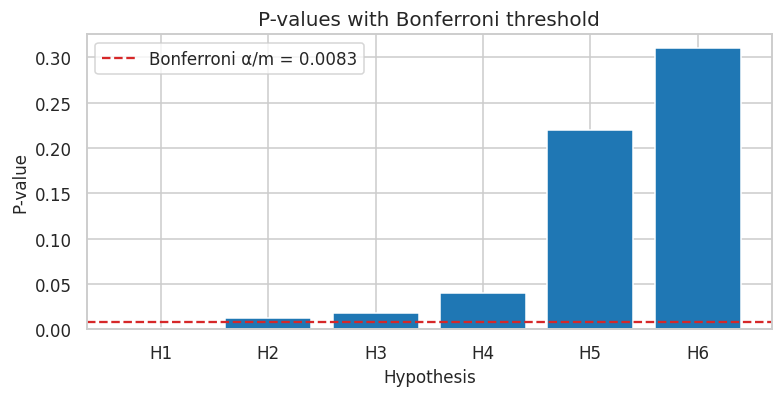

In [93]:
pvals = np.array([.001, .012, .018, .04, .22, .31])
labels = [f"H{i+1}" for i in range(len(pvals))]
threshold = .05/len(pvals)
fig, ax = plt.subplots(figsize=(7, 3.5), constrained_layout=True)
ax.bar(labels, pvals, color=["tab:red" if p < threshold else "tab:blue" for p in pvals])
ax.axhline(threshold, color="tab:red", linestyle="--", label=f"Bonferroni α/m = {threshold:.4f}")
ax.set(title="P-values with Bonferroni threshold", xlabel="Hypothesis", ylabel="P-value")
ax.legend()
plt.show()
assert threshold < .05

### Lab 42 — Optimize a scalar function

**Goal:** Find a minimum and visualize the objective around it.

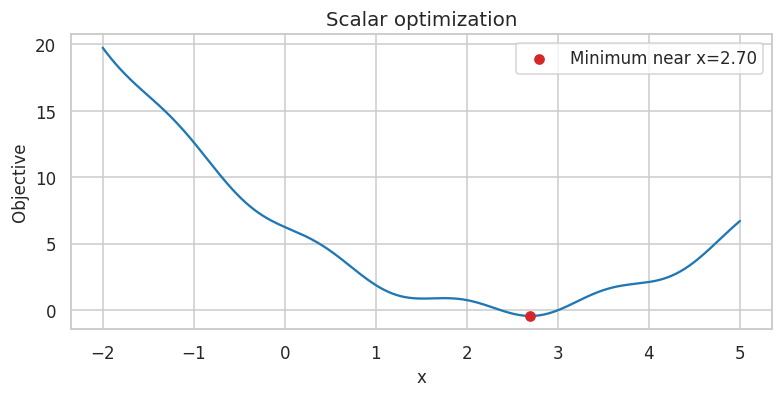

success: True x*: 2.6988 f(x*): -0.4505


In [94]:
f = lambda x: (x-2.5)**2 + .5*np.sin(4*x)
res = optimize.minimize_scalar(f, bounds=(-2, 5), method="bounded")
grid = np.linspace(-2, 5, 300)
fig, ax = plt.subplots(figsize=(7, 3.5), constrained_layout=True)
ax.plot(grid, [f(v) for v in grid], color="tab:blue")
ax.scatter([res.x], [res.fun], color="tab:red", zorder=3, label=f"Minimum near x={res.x:.2f}")
ax.set(title="Scalar optimization", xlabel="x", ylabel="Objective")
ax.legend()
plt.show()
print("success:", res.success, "x*:", round(res.x, 4), "f(x*):", round(res.fun, 4))
assert res.success

### Lab 43 — Save a figure with Matplotlib

**Goal:** Create a reusable Figure and save it in a temporary path (no extra deliverable file).

In [95]:
from pathlib import Path
fig, ax = plt.subplots(figsize=(5, 3), constrained_layout=True)
ax.plot([1,2,3,4], [1,4,2,5], marker="o", color="tab:green")
ax.set(title="Example export", xlabel="Step", ylabel="Value")
tmp_path = Path("/tmp/matplotlib_example.png")
fig.savefig(tmp_path, dpi=120, bbox_inches="tight")
plt.close(fig)
print("Saved figure:", tmp_path.exists(), "bytes:", tmp_path.stat().st_size)
assert tmp_path.exists() and tmp_path.stat().st_size > 0

Saved figure: True bytes: 22097


### Lab 44 — Version-stable Seaborn barplot configuration

**Goal:** Explicitly state the estimator and errorbar to reduce reliance on defaults.

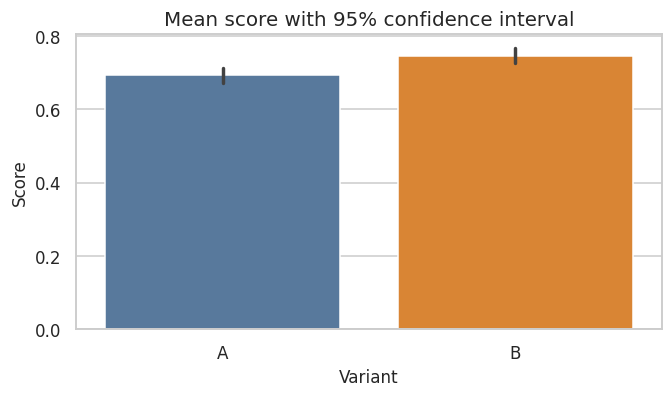

In [96]:
df = pd.DataFrame({"variant": np.repeat(["A","B"], 50),
                   "score": np.r_[np.random.default_rng(31).normal(.70,.08,50),
                                  np.random.default_rng(32).normal(.74,.07,50)]})
fig, ax = plt.subplots(figsize=(6, 3.5), constrained_layout=True)
sns.barplot(data=df, x="variant", y="score", estimator=np.mean, errorbar=("ci", 95), palette=["#4c78a8","#f58518"], hue="variant", legend=False, ax=ax)
ax.set(title="Mean score with 95% confidence interval", xlabel="Variant", ylabel="Score")
plt.show()
assert df["variant"].nunique() == 2

### Lab 45 — Correlation does not imply causation

**Goal:** Visualize a strong association while remembering that a third variable may drive both.

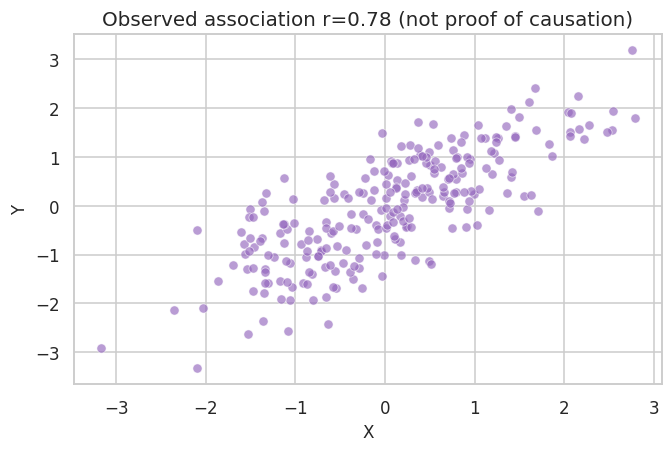

In [97]:
rng = np.random.default_rng(33)
z = rng.normal(size=250)
x = z + rng.normal(scale=.5, size=250)
y = z + rng.normal(scale=.5, size=250)
fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
sns.scatterplot(x=x, y=y, alpha=.65, ax=ax, color="tab:purple")
r = np.corrcoef(x,y)[0,1]
ax.set(title=f"Observed association r={r:.2f} (not proof of causation)", xlabel="X", ylabel="Y")
plt.show()
assert r > .5

### Lab 46 — Group-aware visualization of uncertainty

**Goal:** Show group sample sizes alongside estimates.

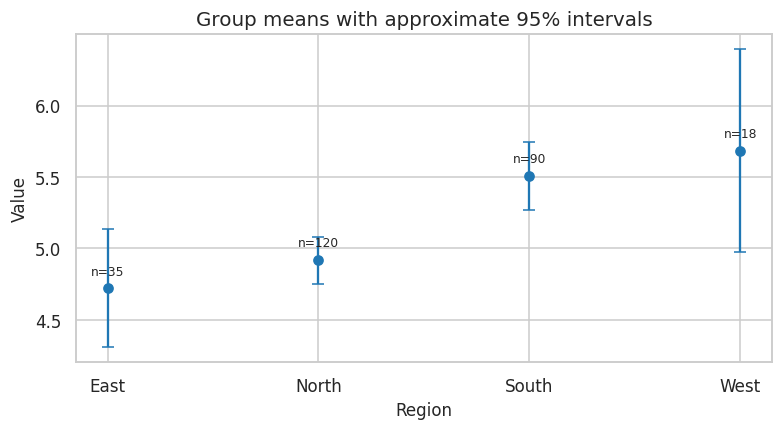

In [98]:
rng = np.random.default_rng(34)
df = pd.DataFrame({"region": np.repeat(["North","South","East","West"], [120,90,35,18]),
                   "value": np.r_[rng.normal(5,1,120), rng.normal(5.5,1.2,90), rng.normal(4.8,1.1,35), rng.normal(6,1.5,18)]})
summary = df.groupby("region")["value"].agg(["mean","count","std"])
summary["se"] = summary["std"]/np.sqrt(summary["count"])
fig, ax = plt.subplots(figsize=(7, 3.8), constrained_layout=True)
ax.errorbar(summary.index, summary["mean"], yerr=1.96*summary["se"], fmt="o", capsize=4, color="tab:blue")
for i, (region, row) in enumerate(summary.iterrows()):
    ax.annotate(f"n={int(row['count'])}", (i, row["mean"]), xytext=(0,9), textcoords="offset points", ha="center", fontsize=8)
ax.set(title="Group means with approximate 95% intervals", xlabel="Region", ylabel="Value")
plt.show()
assert summary["count"].sum() == len(df)

## 8. Complete LaTeX Formula & Plot Reference Gallery

Here is a clean rendering of key mathematical formulas alongside reference examples of different plot categories.

### Key Statistical Formulas

- **Z-Score Standardization**:
  $$z = \frac{x - \mu}{\sigma}$$

- **Standard Error of the Mean (SEM)**:
  $$\text{SEM} = \frac{s}{\sqrt{n}}$$

- **Pearson Correlation Coefficient ($r$)**:
  $$r = \frac{\text{Cov}(X, Y)}{s_X s_Y}$$

- **Welch's $t$-Statistic**:
  $$t = \frac{\bar{x}_1 - \bar{x}_2}{\sqrt{\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}}}$$

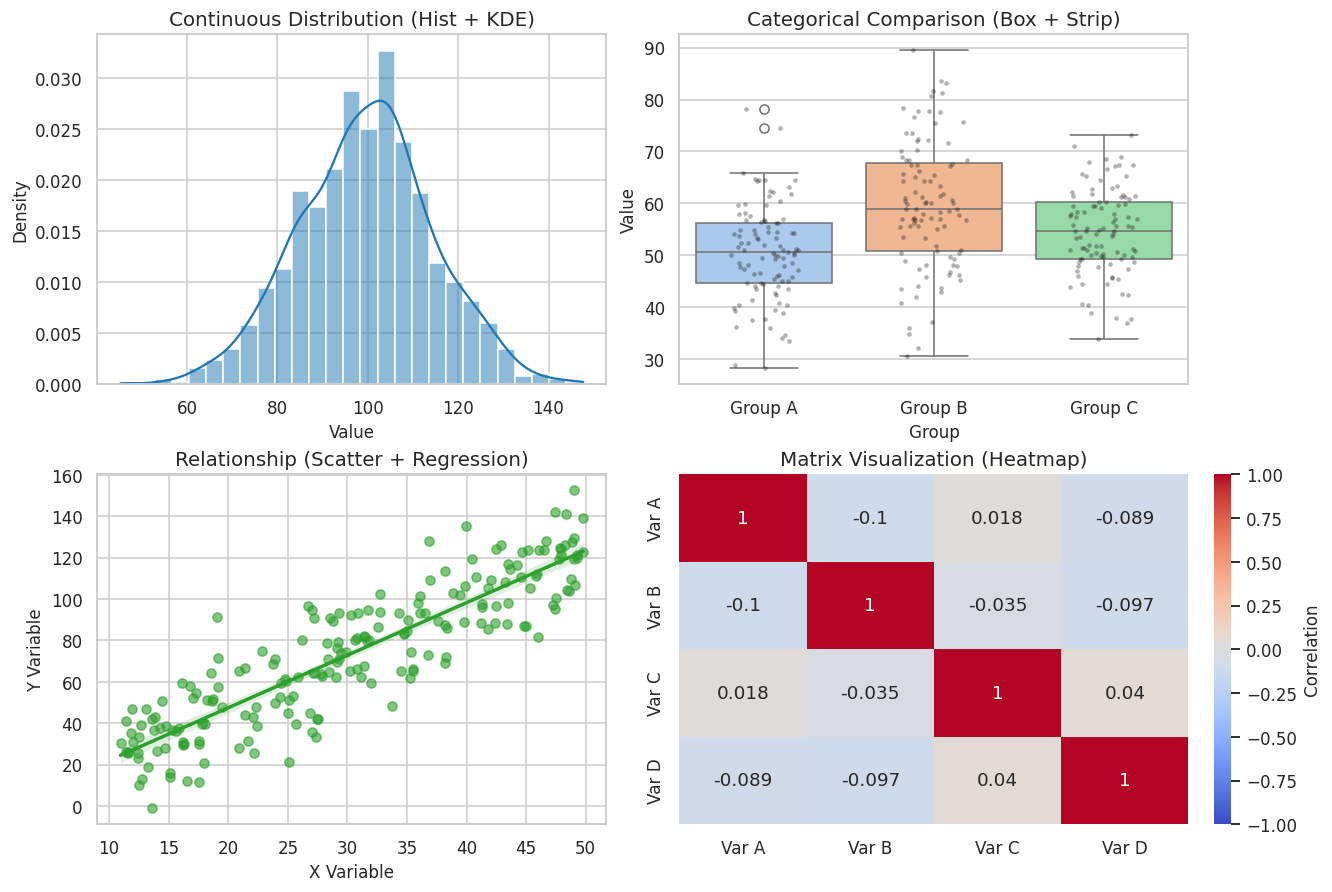

In [99]:
# @title Visual Reference: Continuous Distribution, Categorical, and Correlation Plots
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)

# 1. Continuous Distribution (Histogram + KDE)
rng = np.random.default_rng(42)
data_dist = rng.normal(loc=100, scale=15, size=1000)
sns.histplot(data_dist, kde=True, color="tab:blue", stat="density", ax=axes[0, 0])
axes[0, 0].set(title="Continuous Distribution (Hist + KDE)", xlabel="Value", ylabel="Density")

# 2. Categorical Comparison (Boxplot with Jitter)
categories = ['Group A', 'Group B', 'Group C']
cat_data = pd.DataFrame({
    'Group': np.repeat(categories, 100),
    'Value': np.concatenate([rng.normal(50, 10, 100), rng.normal(60, 12, 100), rng.normal(55, 8, 100)])
})
sns.boxplot(data=cat_data, x='Group', y='Value', ax=axes[0, 1], palette="pastel", hue='Group', legend=False)
sns.stripplot(data=cat_data, x='Group', y='Value', ax=axes[0, 1], color="black", alpha=0.3, size=3, jitter=0.2)
axes[0, 1].set(title="Categorical Comparison (Box + Strip)")

# 3. Relationship Plot (Scatter with Regression Line)
x_val = rng.uniform(10, 50, 200)
y_val = 2.5 * x_val + rng.normal(0, 15, 200)
sns.regplot(x=x_val, y=y_val, ax=axes[1, 0], color="tab:green", scatter_kws={'alpha': 0.6})
axes[1, 0].set(title="Relationship (Scatter + Regression)", xlabel="X Variable", ylabel="Y Variable")

# 4. Matrix Heatmap (Correlation Matrix)
matrix_data = pd.DataFrame(rng.normal(size=(100, 4)), columns=['Var A', 'Var B', 'Var C', 'Var D'])
corr_matrix = matrix_data.corr()
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=axes[1, 1], cbar_kws={'label': 'Correlation'})
axes[1, 1].set(title="Matrix Visualization (Heatmap)")

plt.show()

## 7. Interview answer framework

For any chart, SciPy function, or statistical method, answer in this order:

1. **What is it?** Define it precisely.
2. **When do you use it?** Name the data type and question.
3. **Why this method?** Explain what it reveals or estimates.
4. **How do you implement it?** Name the API and important arguments.
5. **What assumptions or risks apply?** Include dependence, sample size, outliers, multiplicity, leakage, or visual distortion when relevant.
6. **What would you do next?** Validate with diagnostics, uncertainty, domain knowledge, or a second complementary view.

### Final reminders
- **Plot distributions before fitting assumptions.**
- **Prefer `fig, ax = plt.subplots()` for maintainable Matplotlib code.**
- **Use Seaborn for concise statistical EDA; use Matplotlib for detailed control.**
- **Use SciPy tests only after identifying the estimand and independent unit.**
- **Explicitly label confidence intervals, error bars, units, and denominators.**
- **Correlation, a fitted line, a low p-value, and a colorful chart do not independently prove causation.**
